In [81]:
import scanpy as sc
import numpy as np
import pandas as pd
import random
import sys
import os

sys.path.append("../../../mapqc/")
import mapqc
import plotting

In [3]:
%load_ext lab_black
%load_ext autoreload
%autoreload 2

In [4]:
query_batch = "Sheppard_2020"

In [5]:
kl_parameter = 1

In [7]:
dir_mapped_results = (
    f"../../../results/HLCA/Sheppard/{query_batch}_kl{kl_parameter}_sample_as_batch"
)

In [8]:
adata = sc.read_h5ad(
    f"{dir_mapped_results}/combined_embedding_klweight_{kl_parameter}.h5ad"
)

In [10]:
ref_q_key = "core_or_extension"
ref_cat = "core"
query_cat = "extension"
batch_key = "dataset"
sample_key = "sample"
condition_key = "condition"
coi_healthy = "NML"
coi_disease = "IPF"
coi_disease_2 = "SCD"
emb_key = "X"

In [11]:
adata.obs.loc[adata.obs[ref_q_key] == query_cat, condition_key].unique()

['SCD', 'IPF', 'NML']
Categories (3, object): ['IPF', 'NML', 'SCD']

In [12]:
adata

AnnData object with n_obs × n_vars = 664964 × 30
    obs: 'suspension_type', 'donor_id', 'is_primary_data', 'assay_ontology_term_id', 'cell_type_ontology_term_id', 'development_stage_ontology_term_id', 'disease_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'tissue_ontology_term_id', 'organism_ontology_term_id', 'sex_ontology_term_id', "3'_or_5'", 'BMI', 'age_or_mean_of_age_range', 'age_range', 'anatomical_region_ccf_score', 'ann_coarse_for_GWAS_and_modeling', 'ann_finest_level', 'ann_level_1', 'ann_level_2', 'ann_level_3', 'ann_level_4', 'ann_level_5', 'cause_of_death', 'core_or_extension', 'dataset', 'fresh_or_frozen', 'log10_total_counts', 'lung_condition', 'mixed_ancestry', 'original_ann_level_1', 'original_ann_level_2', 'original_ann_level_3', 'original_ann_level_4', 'original_ann_level_5', 'original_ann_nonharmonized', 'reannotation_type', 'sample', 'scanvi_label', 'sequencing_platform', 'smoking_status', 'study', 'subject_type', 'tissue_coarse_unharmonized', 'tis

In [13]:
print(f"Subsetting query to condition {coi_healthy}")
adata_healthy = adata[
    (adata.obs[ref_q_key] == ref_cat) | (adata.obs[condition_key] == coi_healthy)
].copy()

Subsetting query to condition NML


In [14]:
print(
    "number of query samples left:",
    len(
        adata_healthy.obs.loc[
            adata_healthy.obs[ref_q_key] == query_cat, "sample"
        ].unique()
    ),
)

number of query samples left: 6


In [15]:
adata.shape

(664964, 30)

In [16]:
adata_healthy.shape

(612730, 30)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


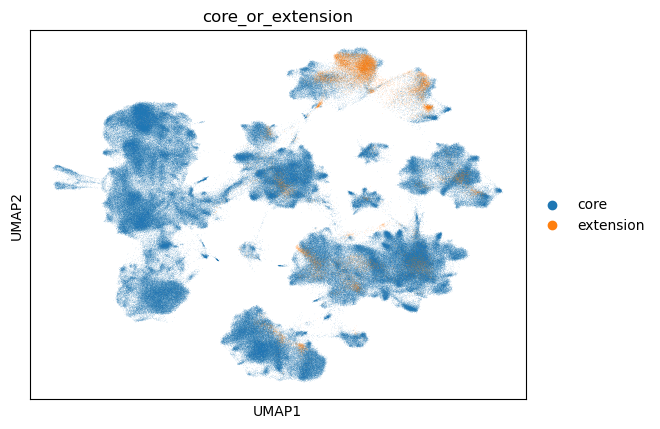

In [17]:
sc.pl.umap(adata_healthy, color=ref_q_key)

#### run MapQC:

In [18]:
(adata_healthy.obs[ref_q_key] == query_cat).sum()

27786

In [19]:
k = int((adata.obs[ref_q_key] == ref_cat).sum() / 200)
max_k = int(k * 1.2)
n_nhoods_healthy = int((adata_healthy.obs[ref_q_key] == query_cat).sum() / k * 20)

In [20]:
print(f"n nhoods healthy: {n_nhoods_healthy}, k: {k}, max k: {max_k}")

n nhoods healthy: 190, k: 2924, max k: 3508


In [21]:
query_cell_idc_healthy = np.where(adata_healthy.obs[ref_q_key] == query_cat)[0].tolist()
random.seed(0)
center_cell_idc_healthy = random.sample(query_cell_idc_healthy, k=n_nhoods_healthy)
center_cells_healthy = np.array(
    adata_healthy.obs.iloc[center_cell_idc_healthy, :].index
)

In [22]:
results_healthy = mapqc.mapQC_results(
    adata=adata_healthy,
    center_cells=center_cells_healthy,
    k=k,
    emb_key=emb_key,
    ref_q_key=ref_q_key,
    ref_cat=ref_cat,
    query_cat=query_cat,
    batch_key=batch_key,
    exclude_same_batch_for_ref_samples=True,
    use_adaptive_k=True,
    max_k=max_k,
    min_n_samples_q=1,  # NOTE THAT THIS IS NOT THE DEFAULT...
)

In [23]:
results_healthy.calculate_sample_dists_to_ref_samples()

190it [04:52,  1.54s/it]

83% of neighborhoods passed filtering. (For more details, see [mapqc_object]._nhood_filtered)



../../../mapqc/mapqc.py:200: RuntimeWarning: Mean of empty slice
  self.mean_sample_dists_to_ref = np.nanmean(self.intersample_distances, axis=0)
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1577: RuntimeWarning: All-NaN slice encountered
  result = np.apply_along_axis(_nanquantile_1d, axis, a, q,
../../../mapqc/mapqc.py:226: RuntimeWarning: Mean of empty slice
  nhood_ref_mean_dists = np.nanmean(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1872: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


In [24]:
results_healthy._nhood_filtered.value_counts()

pass                                                158
too few reference samples from different batches     20
too few reference samples                            12
dtype: int64

In [25]:
results_healthy.calculate_nhood_statistics(q=66)

11% of neighborhoods that passed filtering are below the significance threshold alpha=0.05.
For 13% of filtered neighborhoods, >34% of samples are more than two standard deviations above the mean distance from the reference.
0% of query samples (0 sample(s)) consistently do not mix well with the reference.


../../../mapqc/mapqc.py:366: RuntimeWarning: Mean of empty slice
  mean_zscored_q_dist_to_ref = np.nanmean(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1217: RuntimeWarning: All-NaN slice encountered
  return function_base._ureduce(a, func=_nanmedian, keepdims=keepdims,
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1577: RuntimeWarning: All-NaN slice encountered
  result = np.apply_along_axis(_nanquantile_1d, axis, a, q,


In [26]:
results_healthy.calculate_cell_statistics_from_nhoods_using_nhood_stats()

Percentage of query cells in low-mixing neighborhoods: 9.93 (cutoff percentile: 66).


In [27]:
results_healthy.calculate_cell_statistics_using_sample_level_results_per_nhood()

Percentage of query cells showing low sample-mixing: 8.53.


### Plot

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


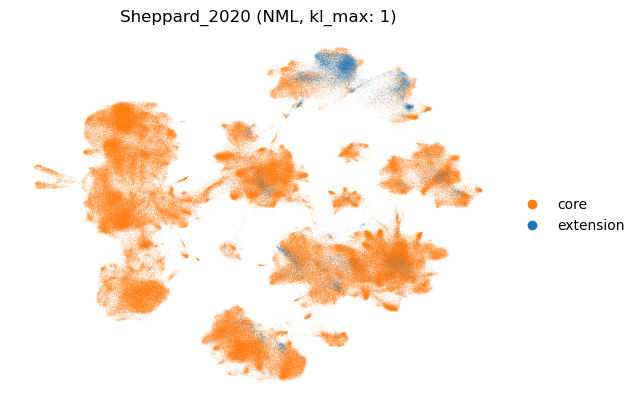

In [28]:
sc.pl.umap(
    results_healthy.adata,
    color=ref_q_key,
    palette={
        results_healthy.ref_cat: "tab:orange",
        results_healthy.query_cat: "tab:blue",
    },
    title=f"{query_batch} ({coi_healthy}, kl_max: {kl_parameter})",
    frameon=False,
)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


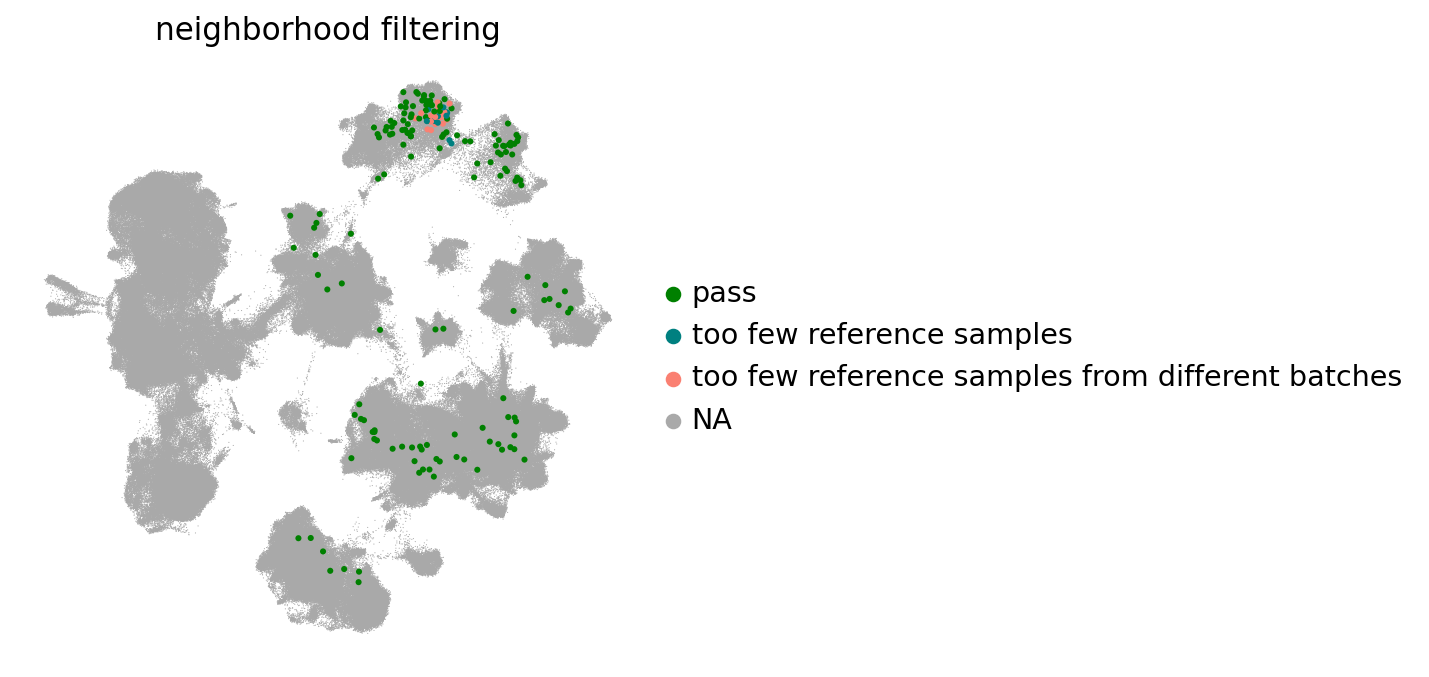

In [29]:
plotting.plot_umap_filtering_info(results_healthy)

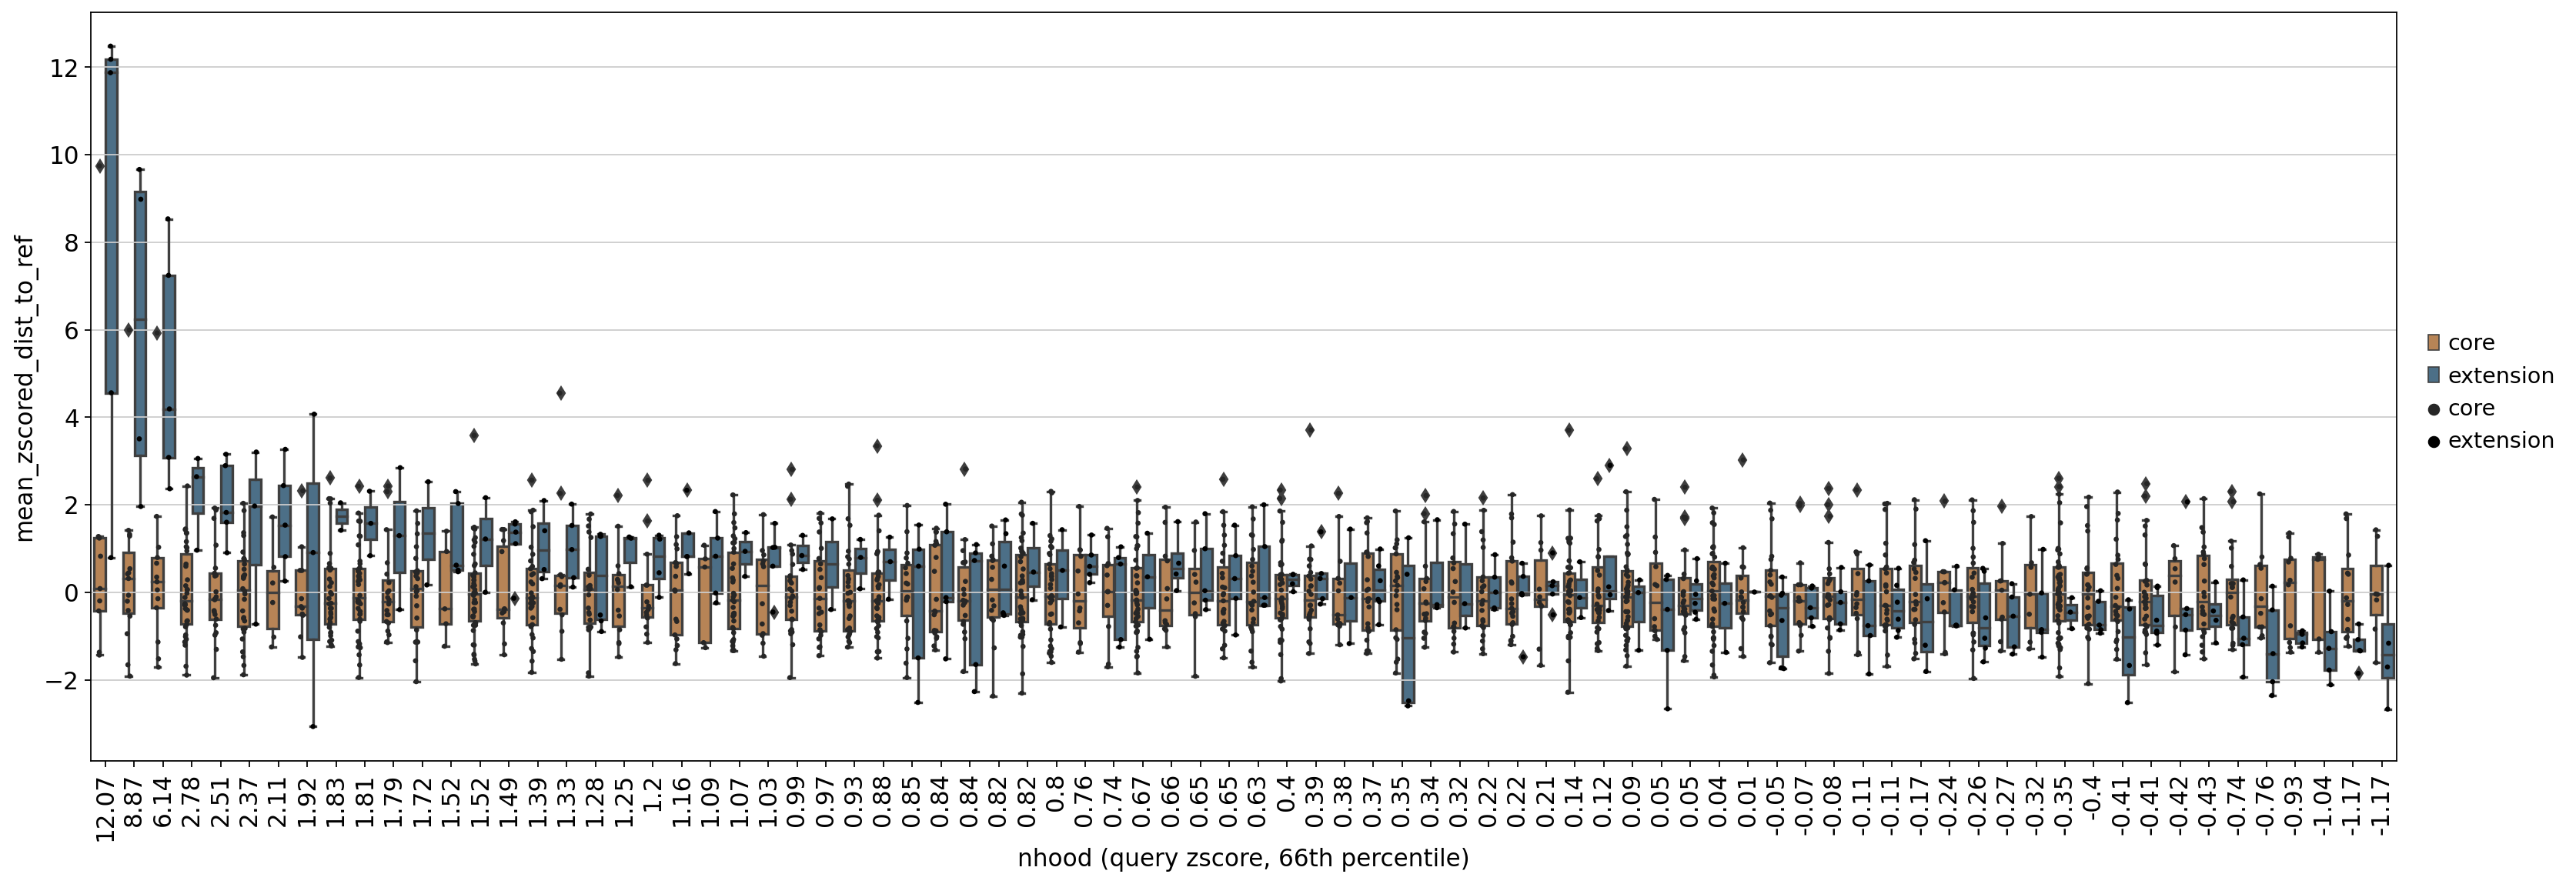

In [30]:
plotting.plot_boxplot_of_ref_vs_q_dists_per_nhood(
    results_healthy, use_zscored_dists=True
)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


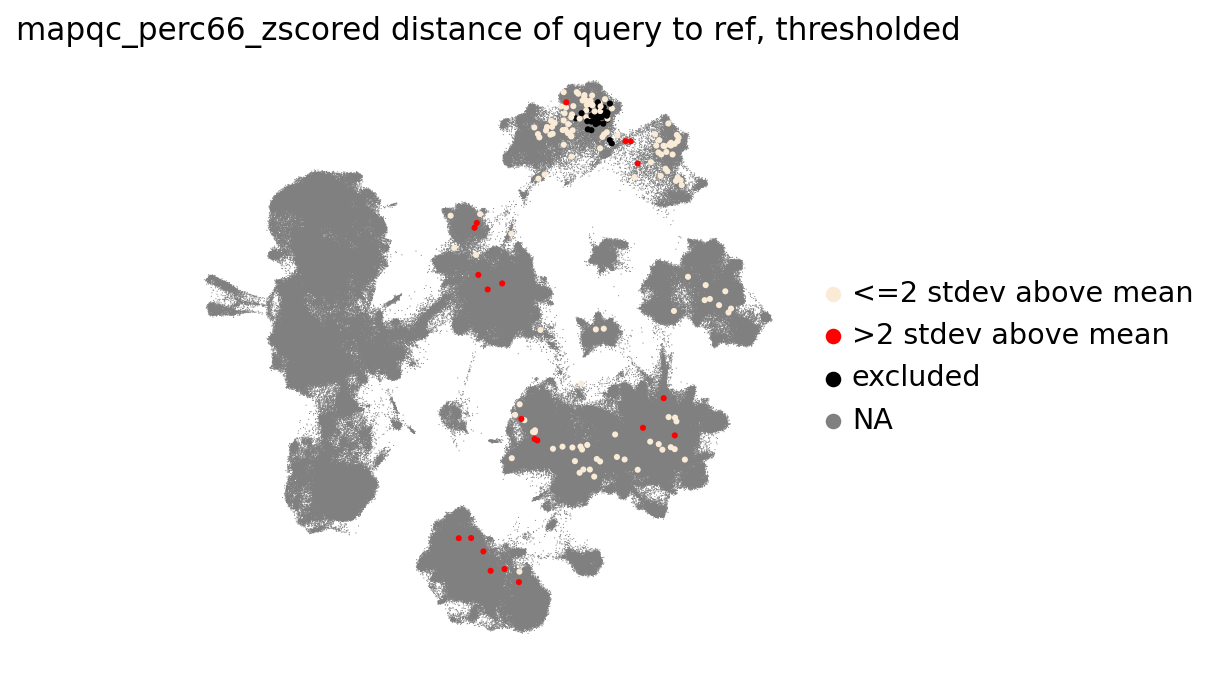

In [31]:
plotting.plot_umap_zscored_q_dist_to_ref(results_healthy, color_by="percq_zscore>2")

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


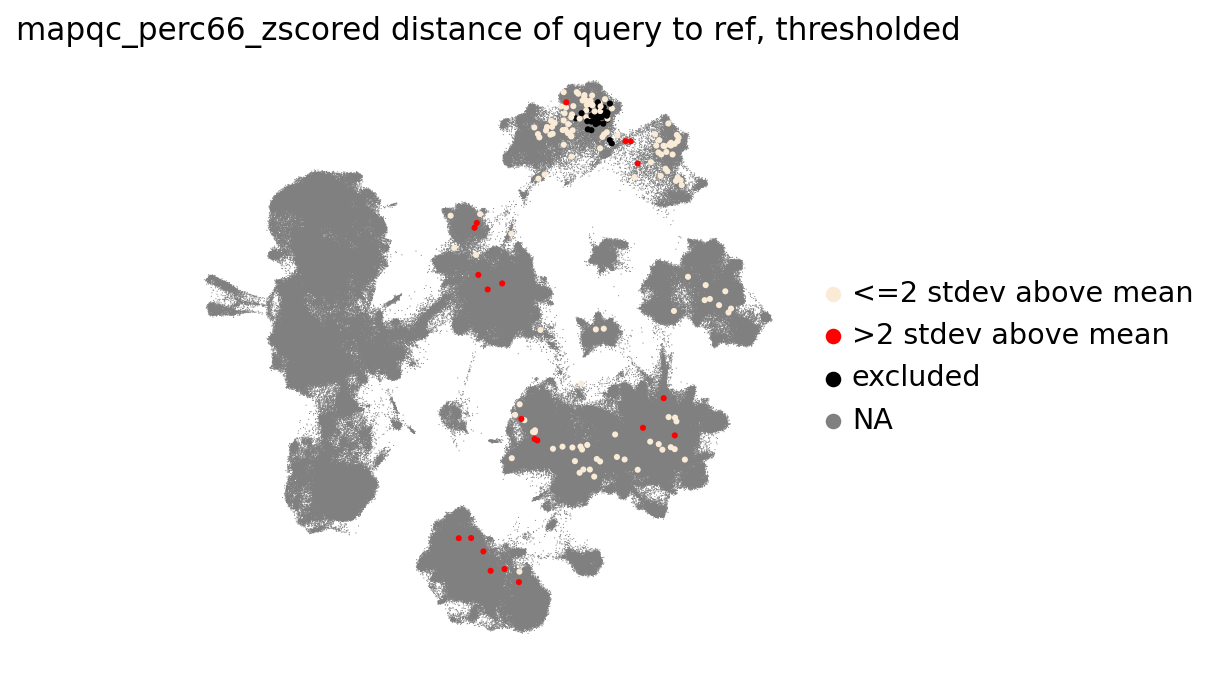

In [32]:
OLD: plotting.plot_umap_zscored_q_dist_to_ref(
    results_healthy, color_by="percq_zscore>2"
)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


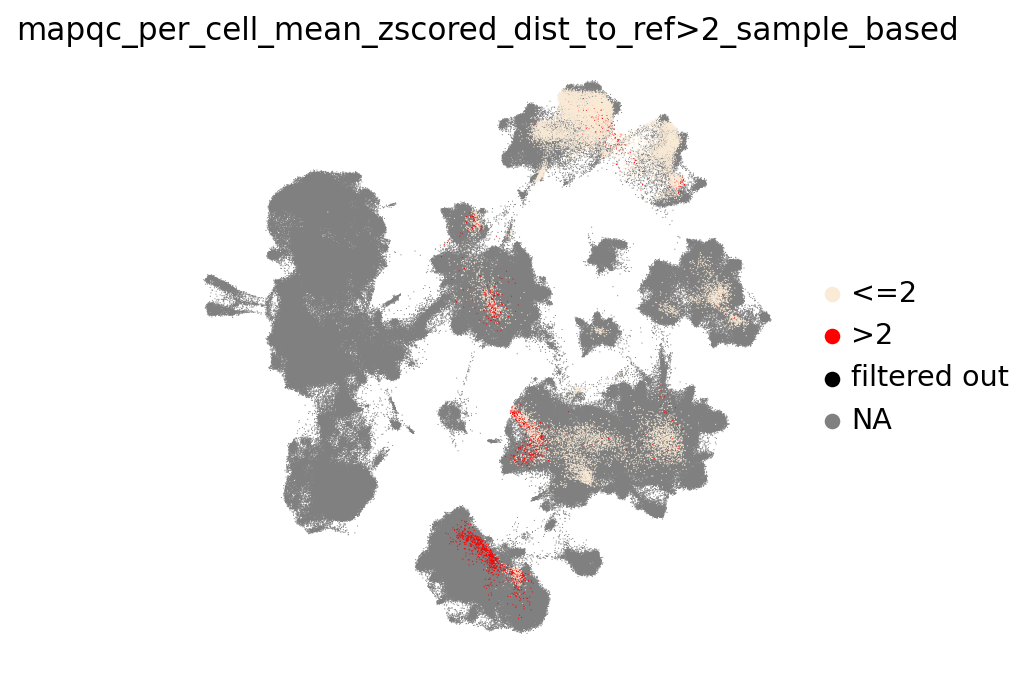

In [33]:
plotting.plot_umap_cell_level_results(results_healthy, size=1)

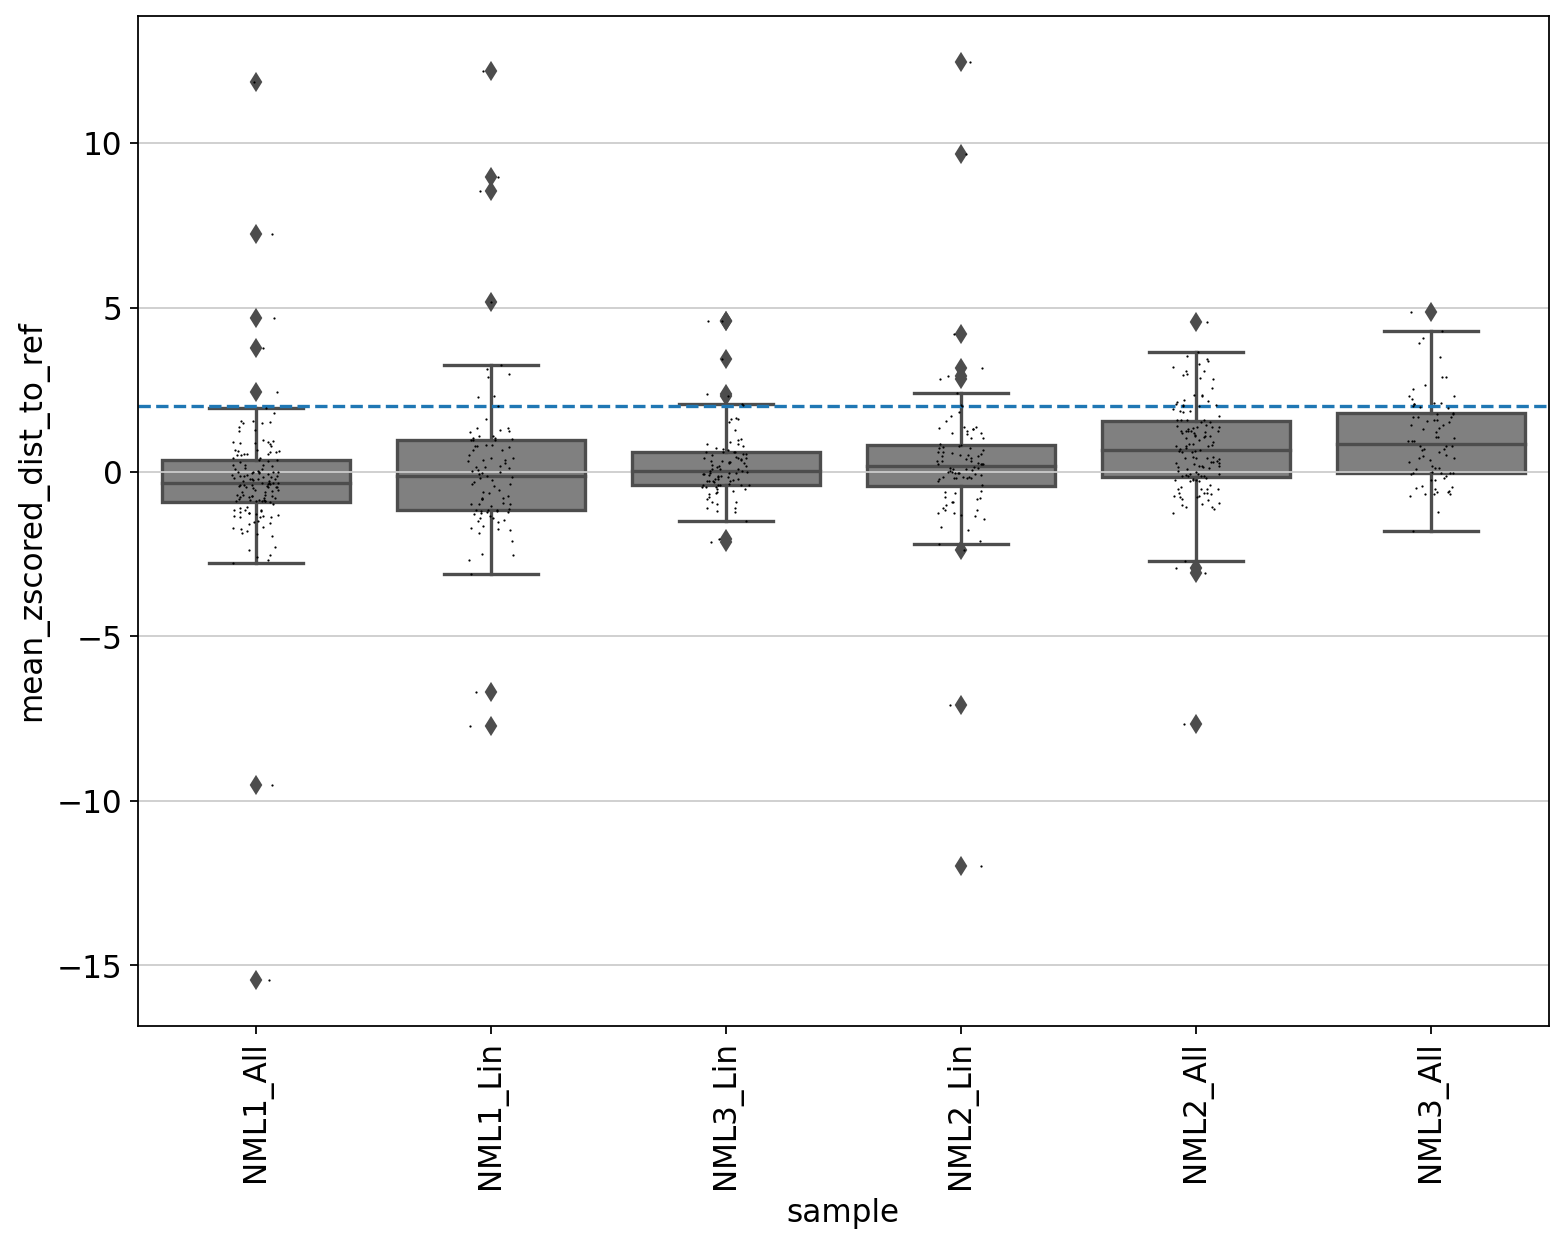

In [34]:
plotting.plot_sample_distances_to_reference(results_healthy)

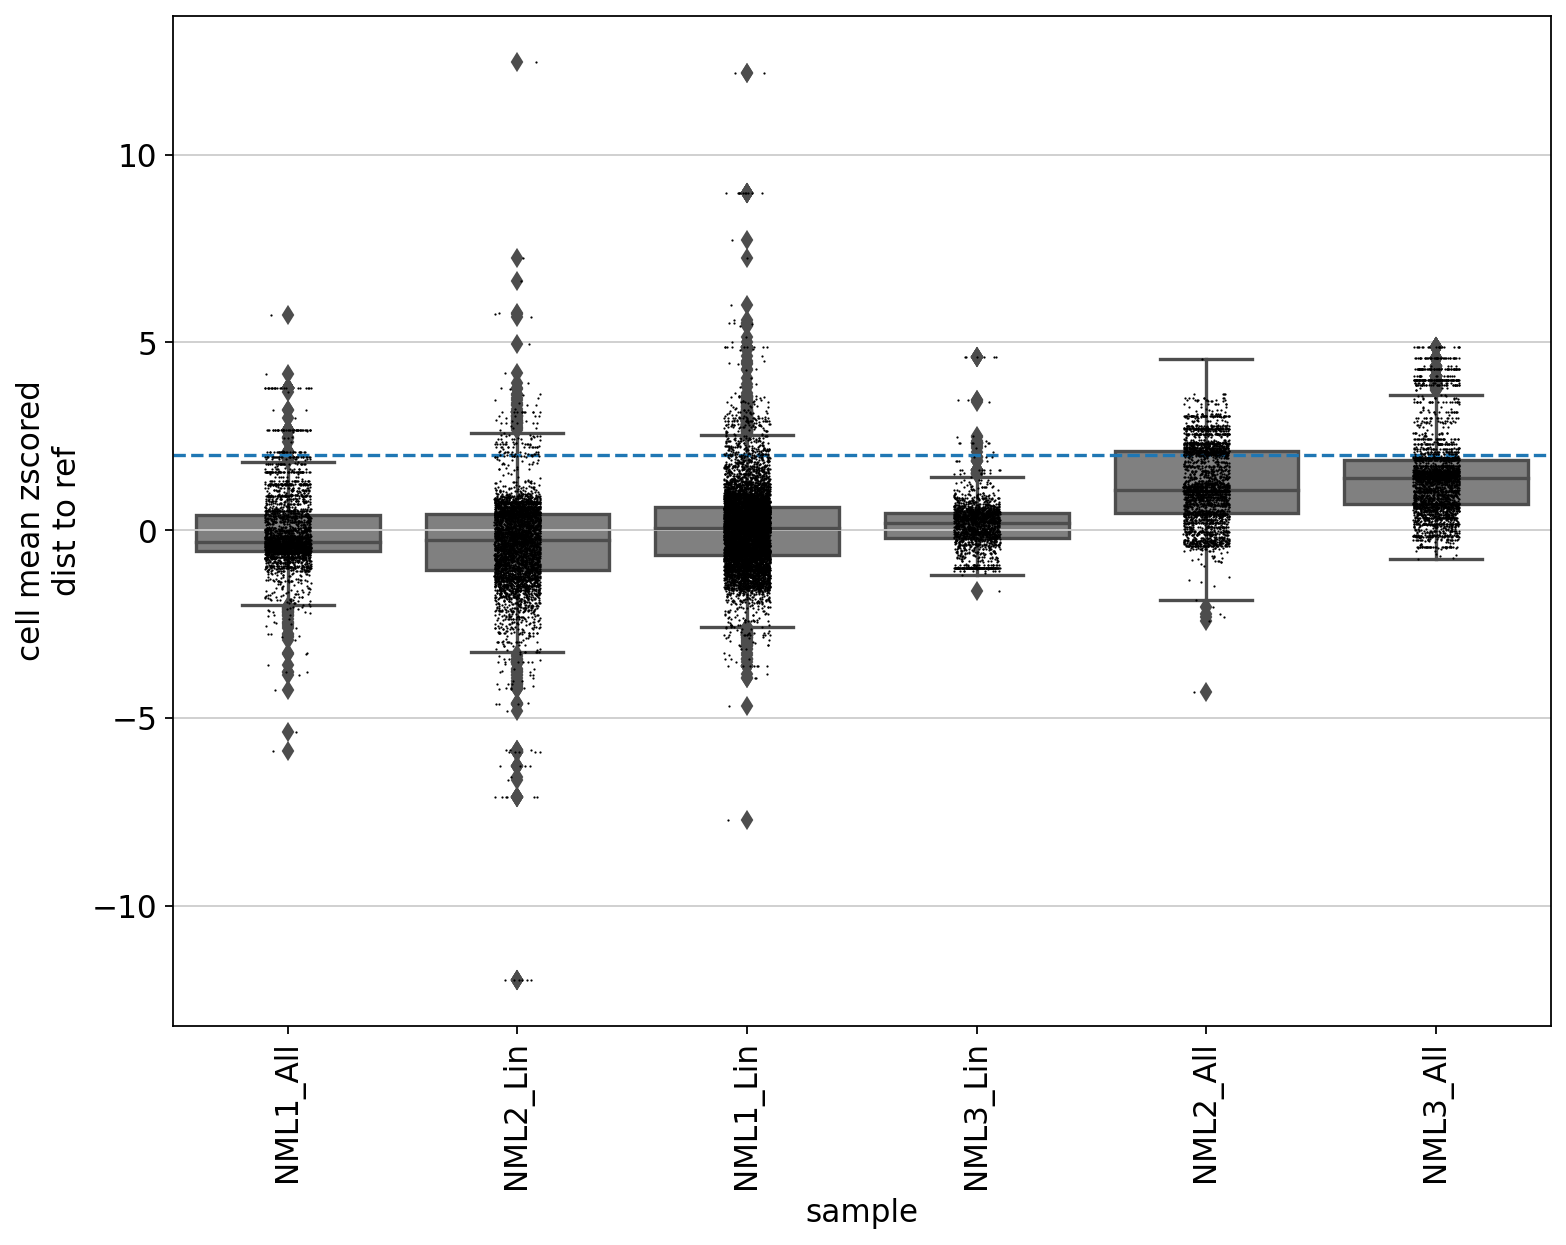

In [35]:
plotting.plot_sample_distances_to_reference_cell_level(results_healthy)

## Disease 1:

In [36]:
print(f"Subsetting query to condition {coi_disease}")
adata_disease = adata[
    (adata.obs[ref_q_key] == ref_cat) | (adata.obs[condition_key] == coi_disease)
].copy()

Subsetting query to condition IPF


In [37]:
print(
    "number of query samples left:",
    len(
        adata_disease.obs.loc[
            adata_disease.obs[ref_q_key] == query_cat, "sample"
        ].unique()
    ),
)

number of query samples left: 5


In [38]:
n_nhoods_disease = int((adata_disease.obs[ref_q_key] == query_cat).sum() / k * 20)

In [39]:
print(f"n nhoods disease: {n_nhoods_disease}")

n nhoods disease: 231


In [40]:
adata.shape

(664964, 30)

In [41]:
adata_disease.shape

(618761, 30)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


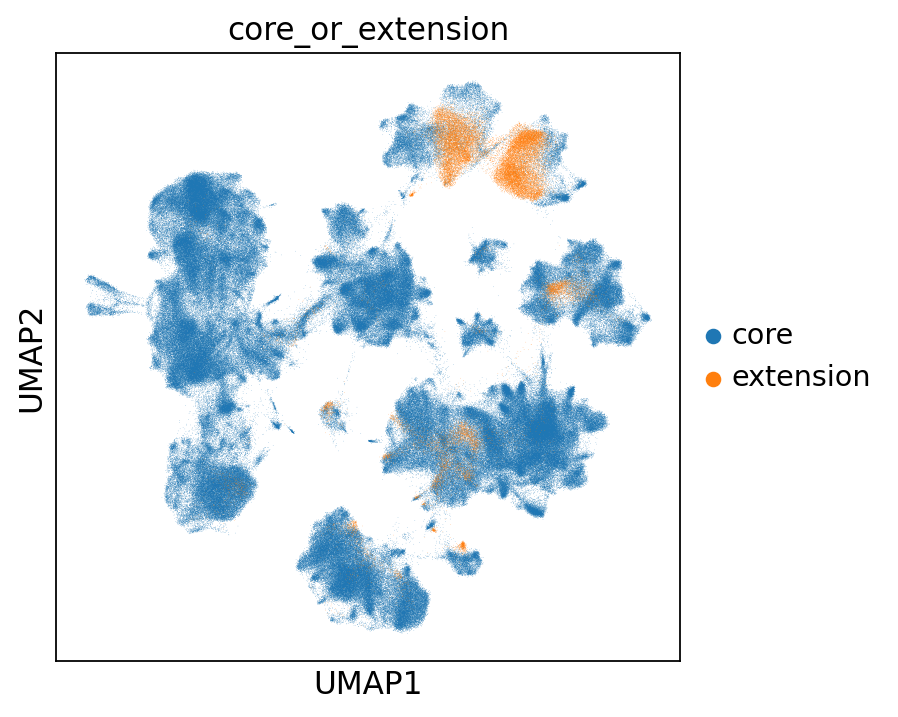

In [42]:
sc.pl.umap(adata_disease, color=ref_q_key)

#### run MapQC:

In [43]:
query_cell_idc_disease = np.where(adata_disease.obs[ref_q_key] == query_cat)[0].tolist()
random.seed(0)
center_cell_idc_disease = random.sample(query_cell_idc_disease, k=n_nhoods_disease)
center_cells_disease = np.array(
    adata_disease.obs.iloc[center_cell_idc_disease, :].index
)

In [44]:
results_disease = mapqc.mapQC_results(
    adata=adata_disease,
    center_cells=center_cells_disease,
    k=k,
    emb_key=emb_key,
    ref_q_key=ref_q_key,
    ref_cat=ref_cat,
    query_cat=query_cat,
    batch_key=batch_key,
    exclude_same_batch_for_ref_samples=True,
    use_adaptive_k=True,
    max_k=max_k,
    min_n_samples_q=1,  # NOTE THAT THIS IS NOT THE DEFAULT AND SHOULD ONLY BE SET SO LOW IF NECESSARY
)

In [45]:
results_disease.calculate_sample_dists_to_ref_samples()

231it [10:15,  2.66s/it]

68% of neighborhoods passed filtering. (For more details, see [mapqc_object]._nhood_filtered)



../../../mapqc/mapqc.py:200: RuntimeWarning: Mean of empty slice
  self.mean_sample_dists_to_ref = np.nanmean(self.intersample_distances, axis=0)
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1577: RuntimeWarning: All-NaN slice encountered
  result = np.apply_along_axis(_nanquantile_1d, axis, a, q,
../../../mapqc/mapqc.py:226: RuntimeWarning: Mean of empty slice
  nhood_ref_mean_dists = np.nanmean(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1872: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


In [46]:
results_disease._nhood_filtered.value_counts()

pass                                                157
too few reference samples                            41
too few reference samples from different batches     33
dtype: int64

In [47]:
results_disease.calculate_nhood_statistics(q=66)

51% of neighborhoods that passed filtering are below the significance threshold alpha=0.05.
For 42% of filtered neighborhoods, >34% of samples are more than two standard deviations above the mean distance from the reference.
0% of query samples (0 sample(s)) consistently do not mix well with the reference.


../../../mapqc/mapqc.py:366: RuntimeWarning: Mean of empty slice
  mean_zscored_q_dist_to_ref = np.nanmean(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1217: RuntimeWarning: All-NaN slice encountered
  return function_base._ureduce(a, func=_nanmedian, keepdims=keepdims,
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1577: RuntimeWarning: All-NaN slice encountered
  result = np.apply_along_axis(_nanquantile_1d, axis, a, q,


In [48]:
results_disease.calculate_cell_statistics_from_nhoods_using_nhood_stats()

Percentage of query cells in low-mixing neighborhoods: 45.68 (cutoff percentile: 66).


In [49]:
results_disease.calculate_cell_statistics_using_sample_level_results_per_nhood()

Percentage of query cells showing low sample-mixing: 35.38.


### Plot

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


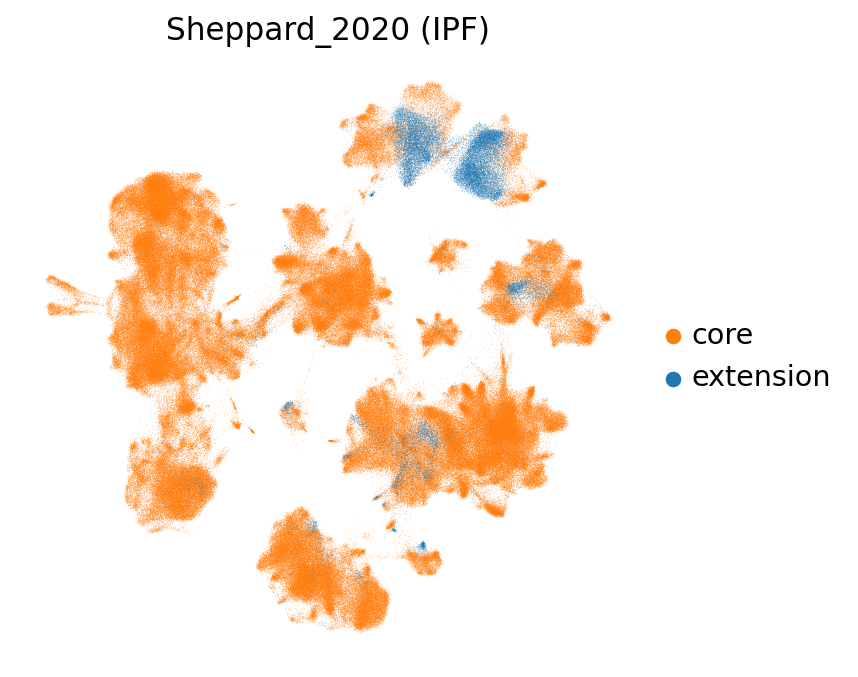

In [50]:
sc.pl.umap(
    results_disease.adata,
    color=ref_q_key,
    palette={
        results_disease.ref_cat: "tab:orange",
        results_disease.query_cat: "tab:blue",
    },
    title=f"{query_batch} ({coi_disease})",
    frameon=False,
)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


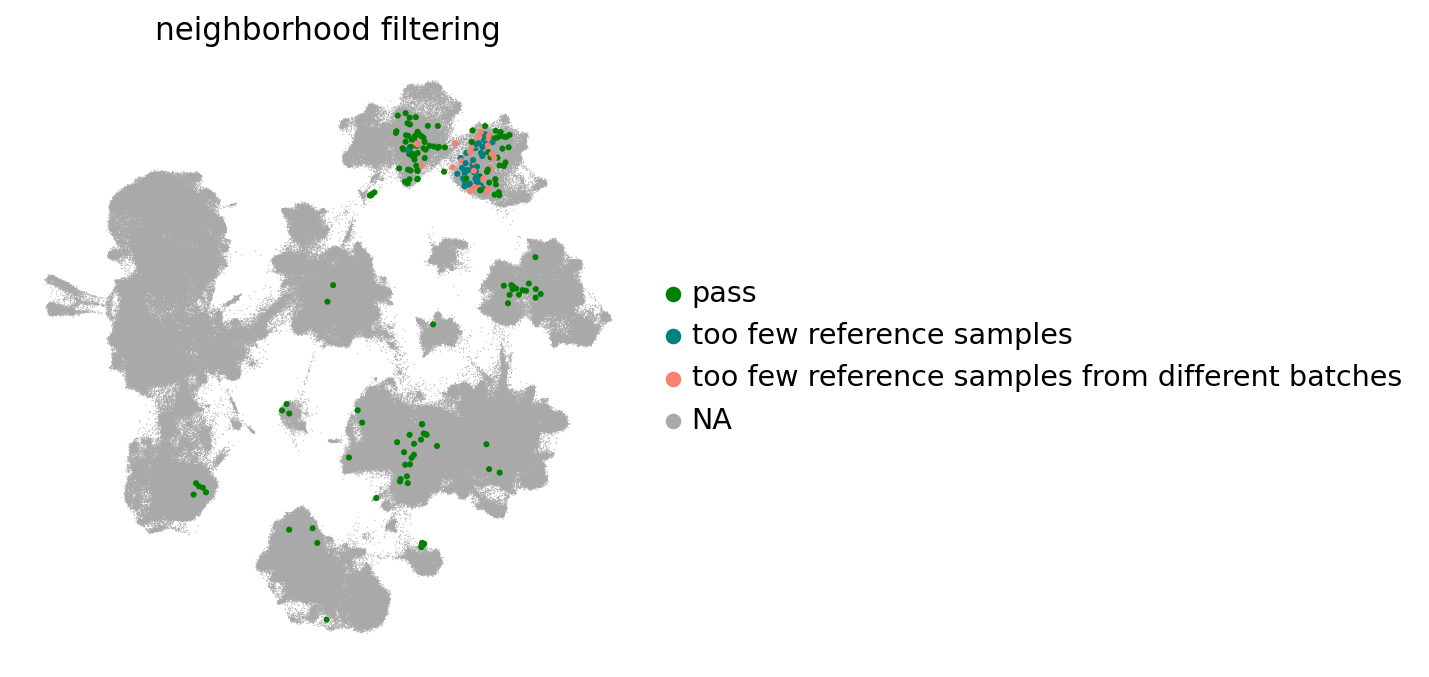

In [51]:
plotting.plot_umap_filtering_info(results_disease)

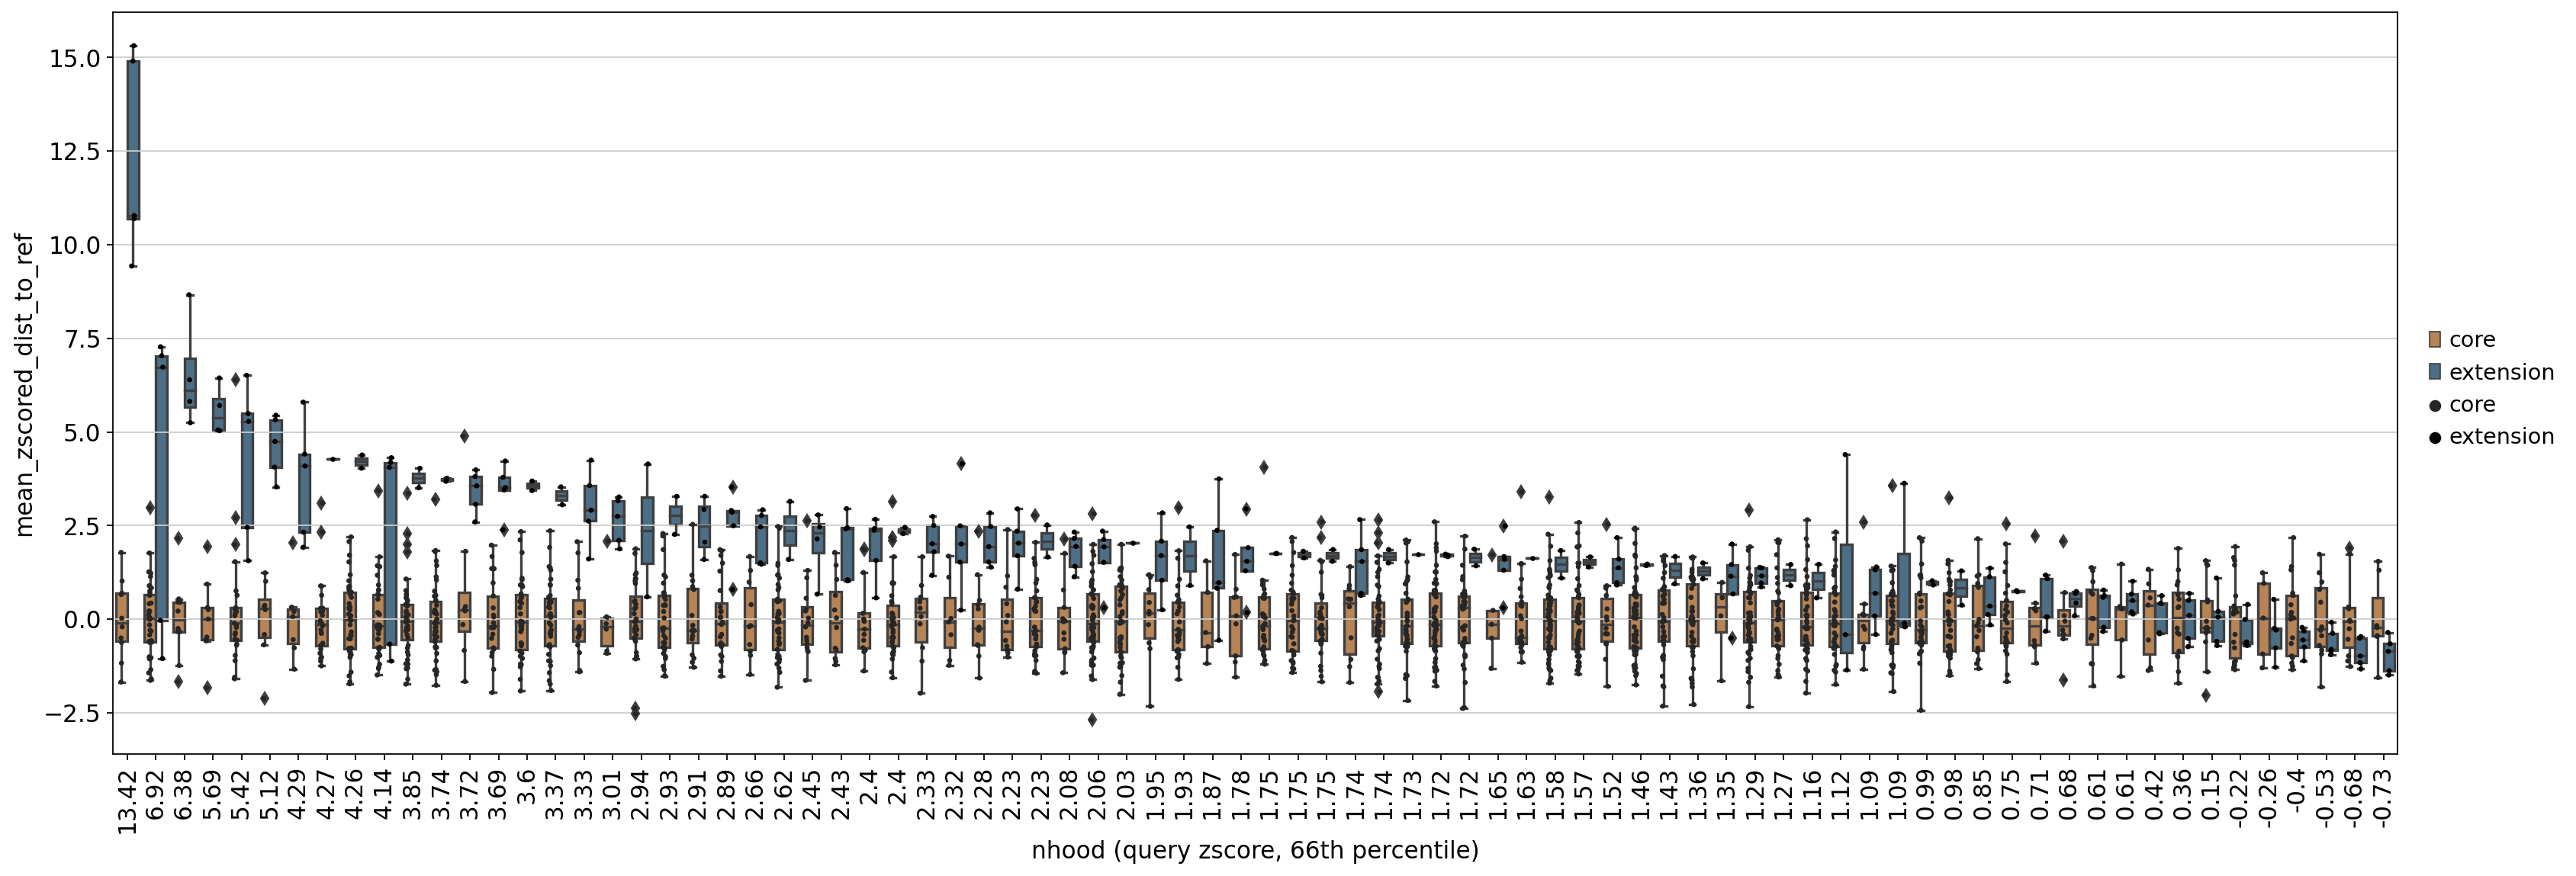

In [52]:
plotting.plot_boxplot_of_ref_vs_q_dists_per_nhood(
    results_disease, use_zscored_dists=True
)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


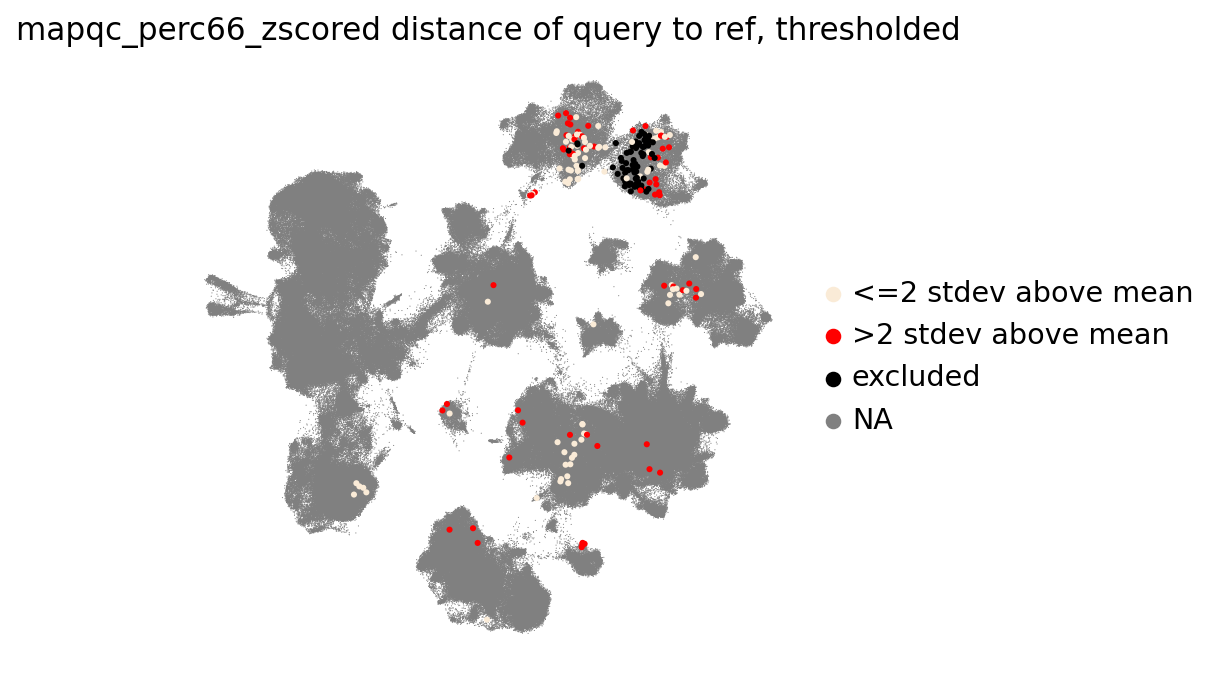

In [53]:
plotting.plot_umap_zscored_q_dist_to_ref(results_disease, color_by="percq_zscore>2")

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


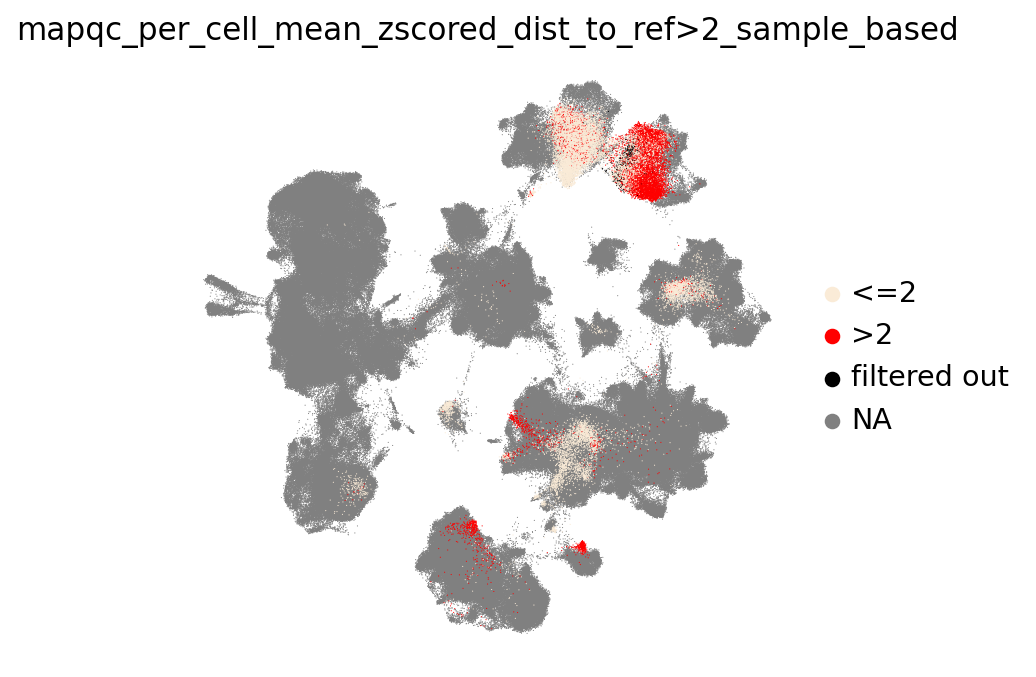

In [54]:
plotting.plot_umap_cell_level_results(results_disease, size=1)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


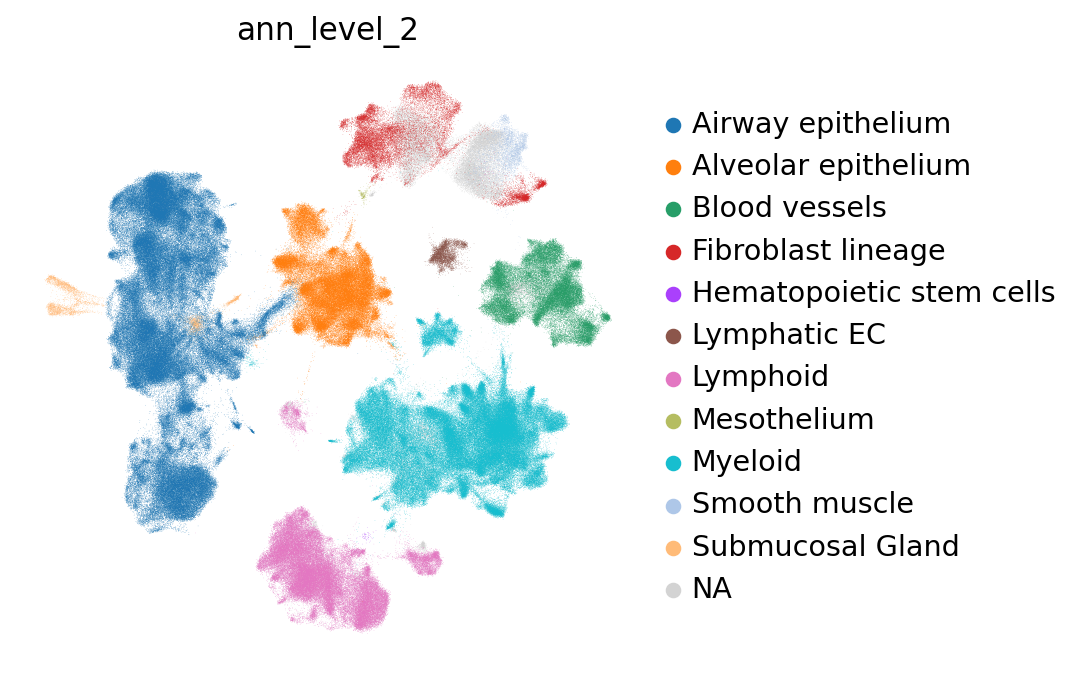

In [55]:
sc.pl.umap(adata_disease, color="ann_level_2", frameon=False)

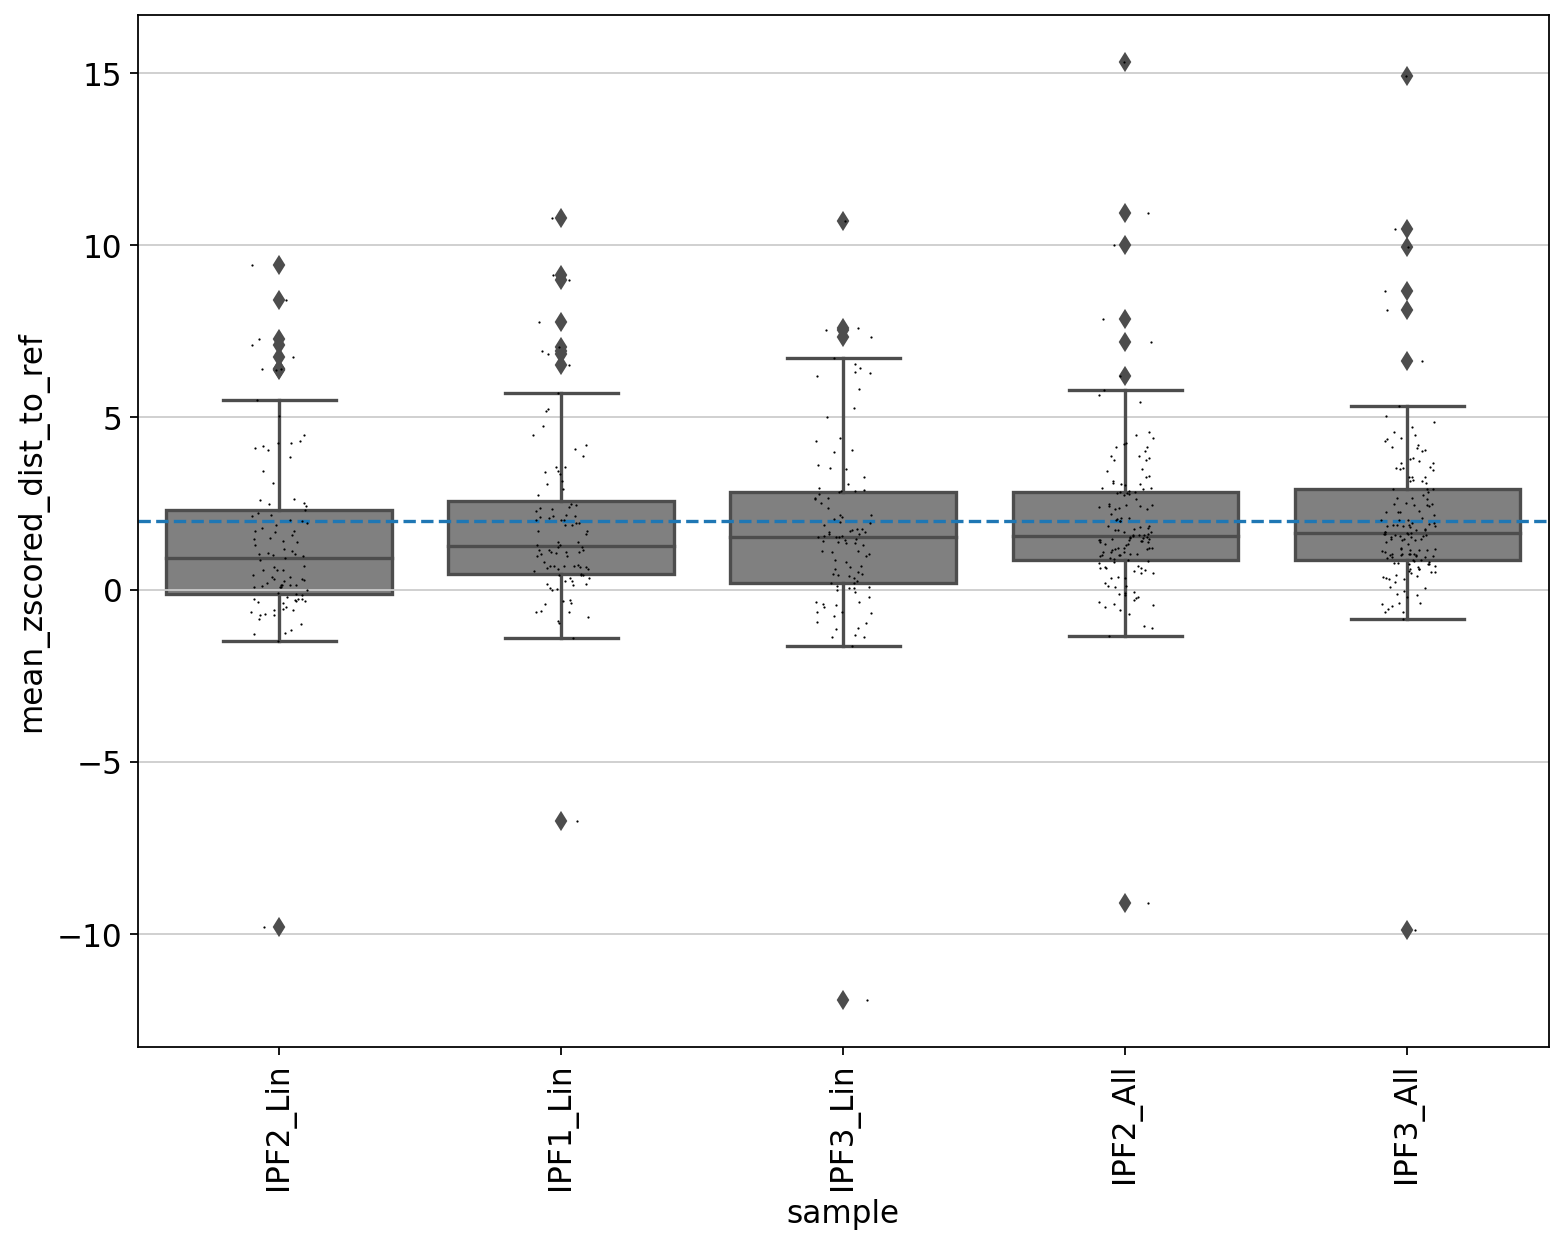

In [56]:
plotting.plot_sample_distances_to_reference(results_disease)

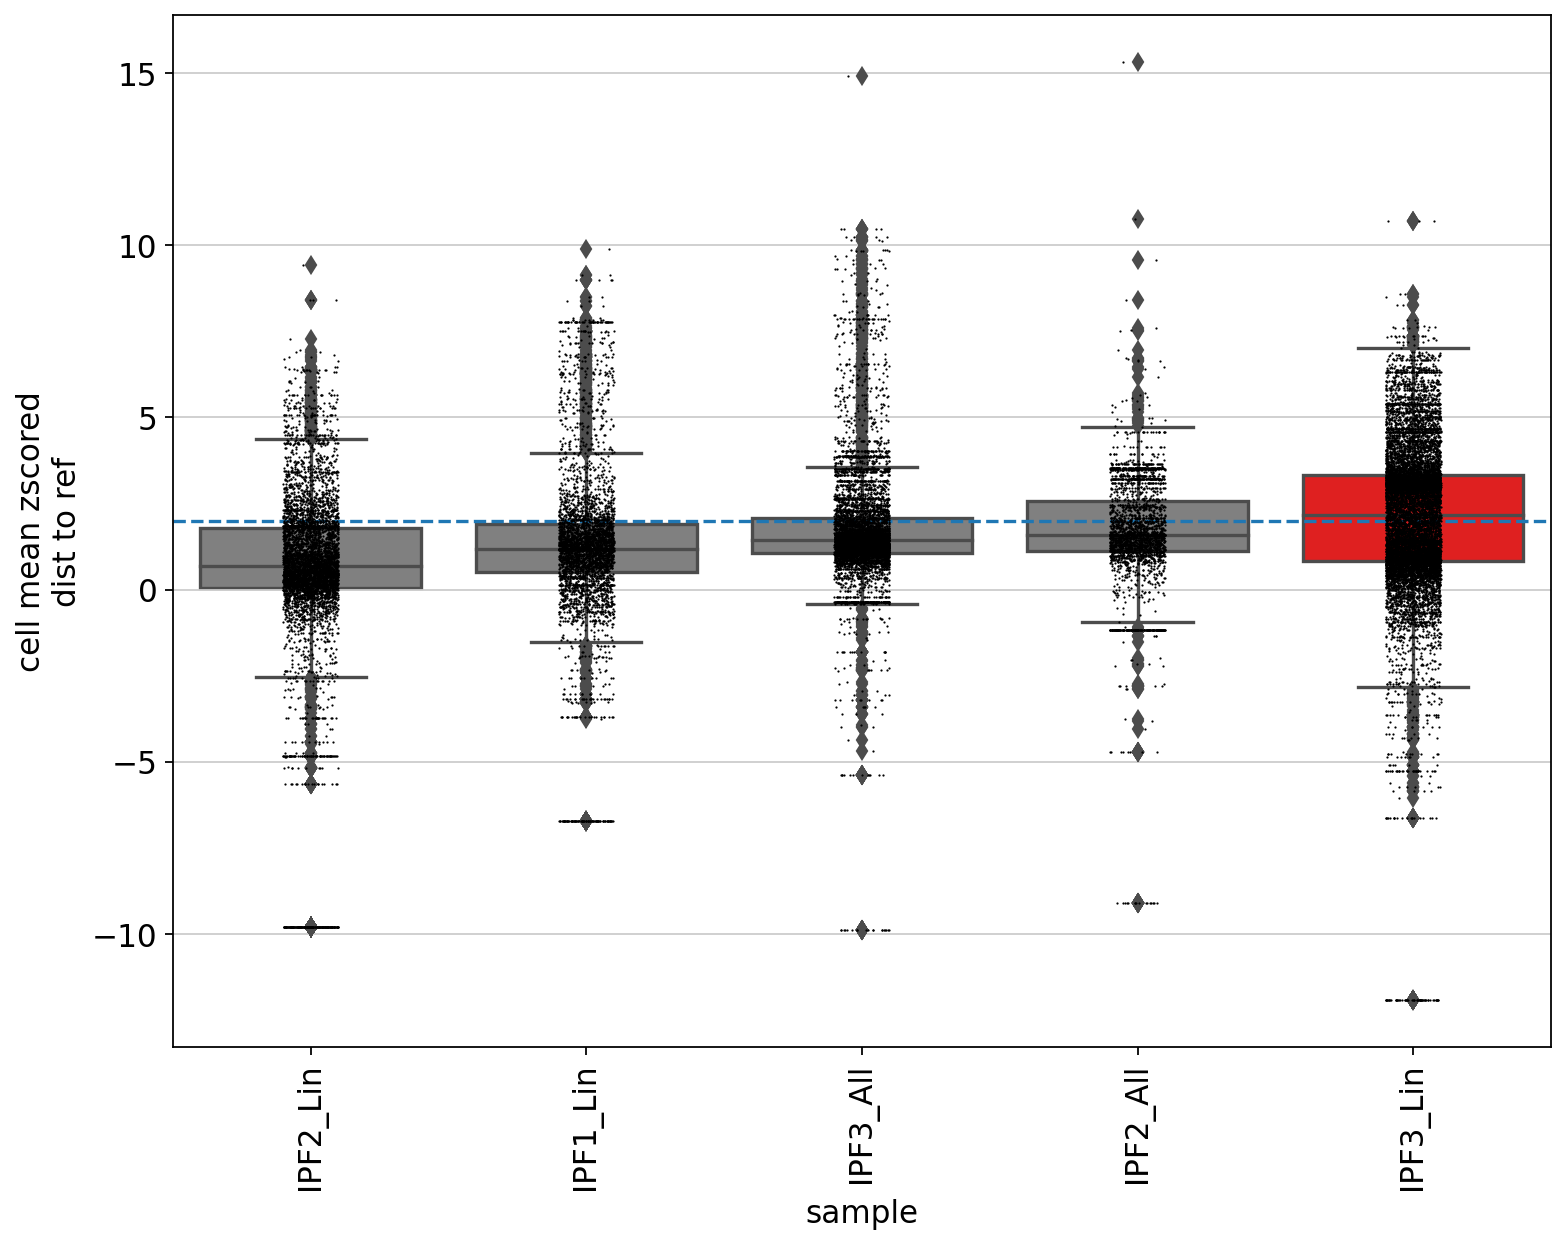

In [57]:
plotting.plot_sample_distances_to_reference_cell_level(results_disease)

## Disease 2:

In [58]:
print(f"Subsetting query to condition {coi_disease_2}")
adata_disease_2 = adata[
    (adata.obs[ref_q_key] == ref_cat) | (adata.obs[condition_key] == coi_disease_2)
].copy()

Subsetting query to condition SCD


In [59]:
print(
    "number of query samples left:",
    len(
        adata_disease_2.obs.loc[
            adata_disease_2.obs[ref_q_key] == query_cat, "sample"
        ].unique()
    ),
)

number of query samples left: 4


In [60]:
adata.shape

(664964, 30)

In [61]:
adata_disease_2.shape

(603361, 30)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


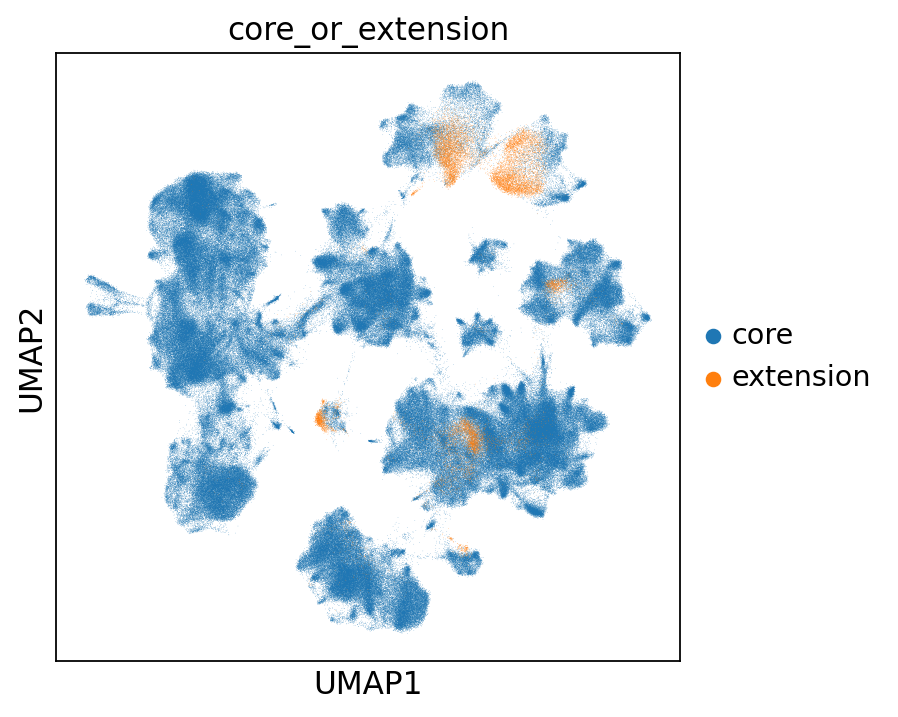

In [62]:
sc.pl.umap(adata_disease_2, color=ref_q_key)

#### run MapQC:

In [63]:
n_nhoods_disease_2 = int((adata_disease_2.obs[ref_q_key] == query_cat).sum() / k * 10)

In [64]:
print(f"n nhoods disease 2: {n_nhoods_disease_2}")

n nhoods disease 2: 62


In [65]:
query_cell_idc_disease_2 = np.where(adata_disease_2.obs[ref_q_key] == query_cat)[
    0
].tolist()
random.seed(0)
center_cell_idc_disease_2 = random.sample(
    query_cell_idc_disease_2, k=n_nhoods_disease_2
)
center_cells_disease_2 = np.array(
    adata_disease_2.obs.iloc[center_cell_idc_disease_2, :].index
)

In [66]:
results_disease_2 = mapqc.mapQC_results(
    adata=adata_disease_2,
    center_cells=center_cells_disease_2,
    k=k,
    emb_key=emb_key,
    ref_q_key=ref_q_key,
    ref_cat=ref_cat,
    query_cat=query_cat,
    batch_key=batch_key,
    exclude_same_batch_for_ref_samples=True,
    use_adaptive_k=True,
    max_k=max_k,
    min_n_samples_q=1,  # NOTE THAT THIS IS NOT THE DEFAULT AND SHOULD ONLY BE SET SO LOW IF NECESSARY
)

In [67]:
results_disease_2.calculate_sample_dists_to_ref_samples()

62it [01:22,  1.33s/it]

87% of neighborhoods passed filtering. (For more details, see [mapqc_object]._nhood_filtered)



../../../mapqc/mapqc.py:200: RuntimeWarning: Mean of empty slice
  self.mean_sample_dists_to_ref = np.nanmean(self.intersample_distances, axis=0)
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1577: RuntimeWarning: All-NaN slice encountered
  result = np.apply_along_axis(_nanquantile_1d, axis, a, q,
../../../mapqc/mapqc.py:226: RuntimeWarning: Mean of empty slice
  nhood_ref_mean_dists = np.nanmean(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1872: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


In [68]:
results_disease_2._nhood_filtered.value_counts()

pass                                                54
too few reference samples from different batches     7
too few reference samples                            1
dtype: int64

In [69]:
results_disease_2.calculate_nhood_statistics(q=66)

15% of neighborhoods that passed filtering are below the significance threshold alpha=0.05.
For 30% of filtered neighborhoods, >34% of samples are more than two standard deviations above the mean distance from the reference.
0% of query samples (0 sample(s)) consistently do not mix well with the reference.


../../../mapqc/mapqc.py:366: RuntimeWarning: Mean of empty slice
  mean_zscored_q_dist_to_ref = np.nanmean(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1217: RuntimeWarning: All-NaN slice encountered
  return function_base._ureduce(a, func=_nanmedian, keepdims=keepdims,
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1577: RuntimeWarning: All-NaN slice encountered
  result = np.apply_along_axis(_nanquantile_1d, axis, a, q,


In [70]:
results_disease_2.calculate_cell_statistics_from_nhoods_using_nhood_stats()

Percentage of query cells in low-mixing neighborhoods: 33.75 (cutoff percentile: 66).


In [71]:
results_disease_2.calculate_cell_statistics_using_sample_level_results_per_nhood()

Percentage of query cells showing low sample-mixing: 26.37.


### Plot

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


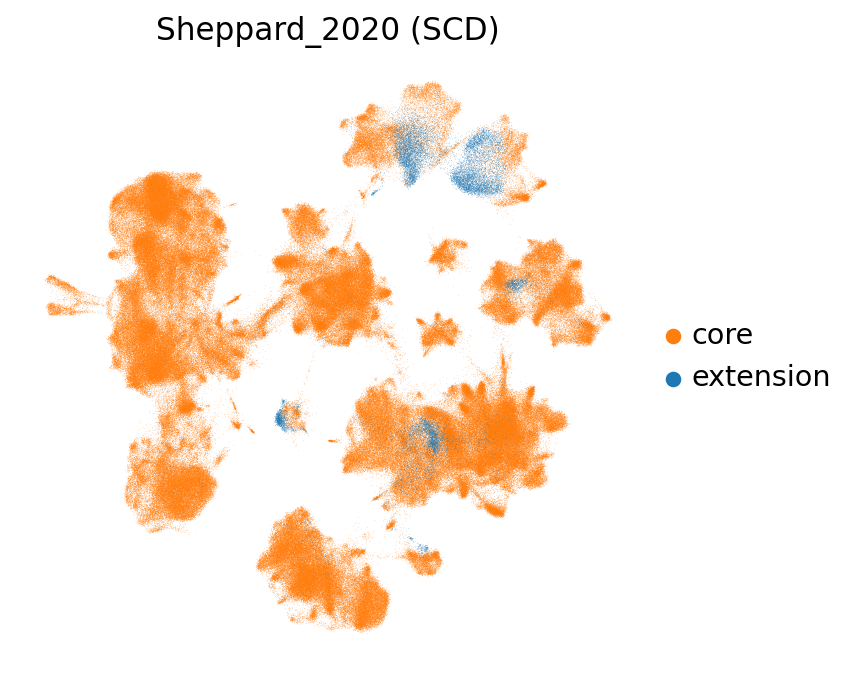

In [72]:
sc.pl.umap(
    results_disease_2.adata,
    color=ref_q_key,
    palette={
        results_disease_2.ref_cat: "tab:orange",
        results_disease_2.query_cat: "tab:blue",
    },
    title=f"{query_batch} ({coi_disease_2})",
    frameon=False,
)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


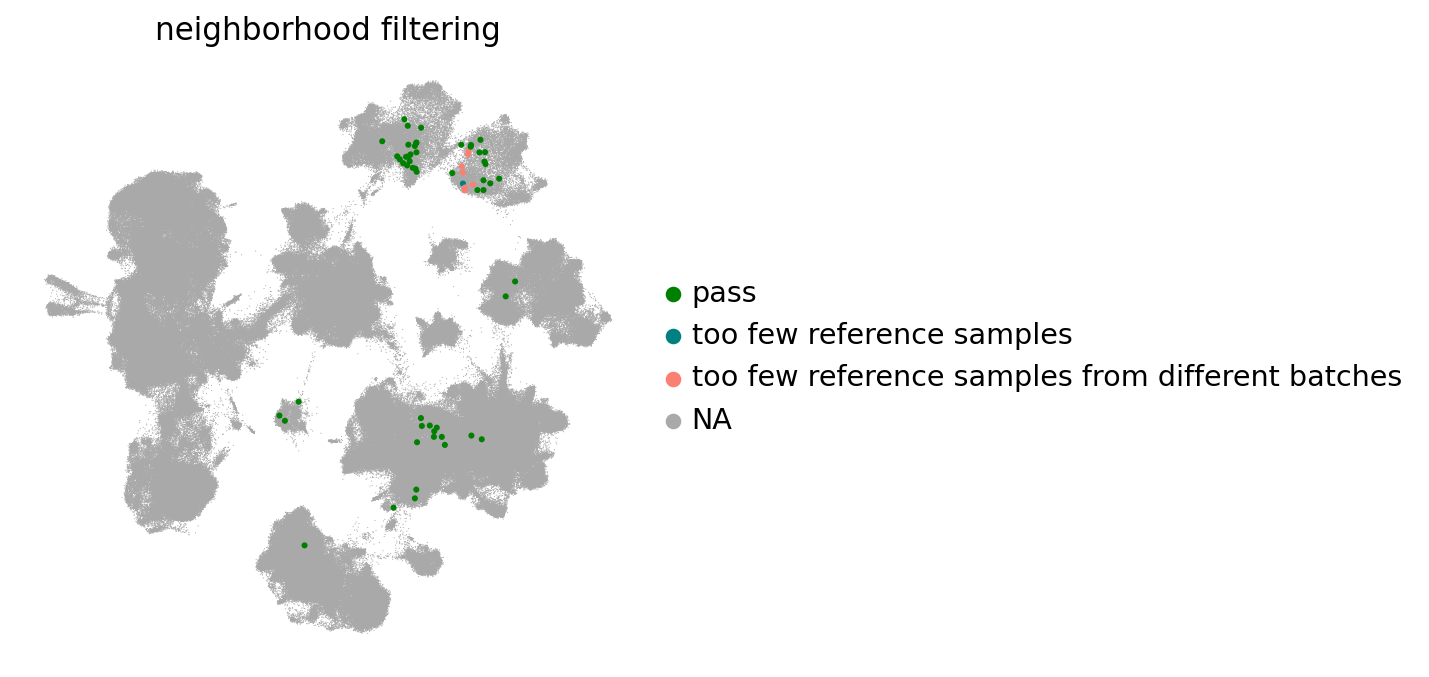

In [73]:
plotting.plot_umap_filtering_info(results_disease_2)

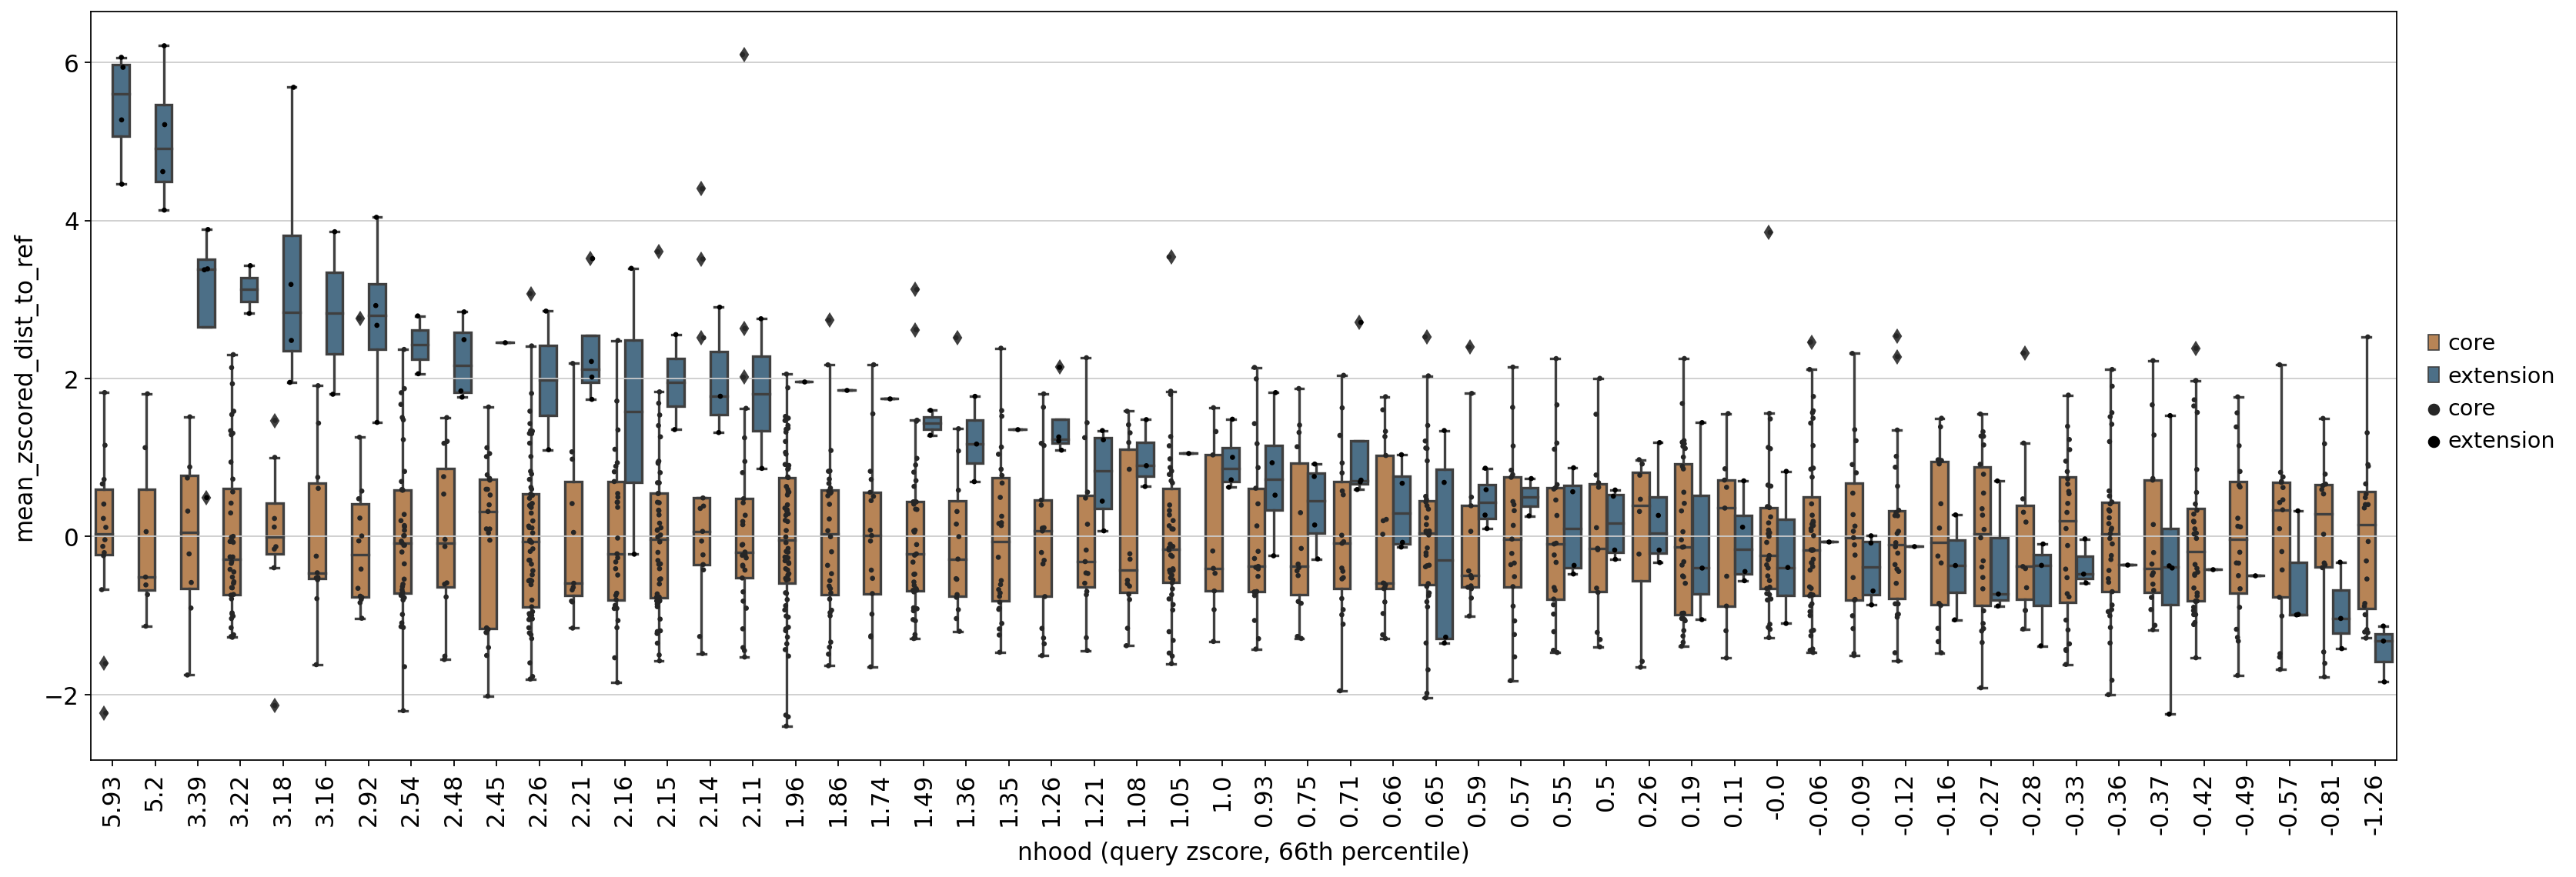

In [74]:
plotting.plot_boxplot_of_ref_vs_q_dists_per_nhood(
    results_disease_2, use_zscored_dists=True
)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


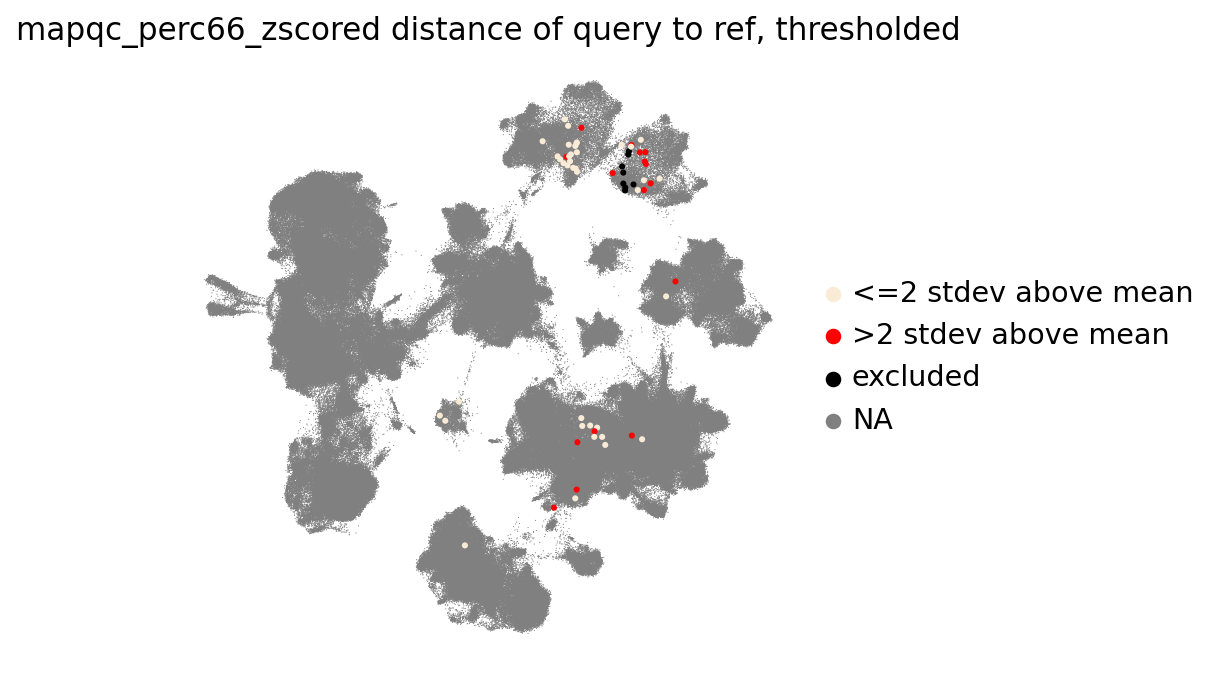

In [75]:
plotting.plot_umap_zscored_q_dist_to_ref(results_disease_2, color_by="percq_zscore>2")

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


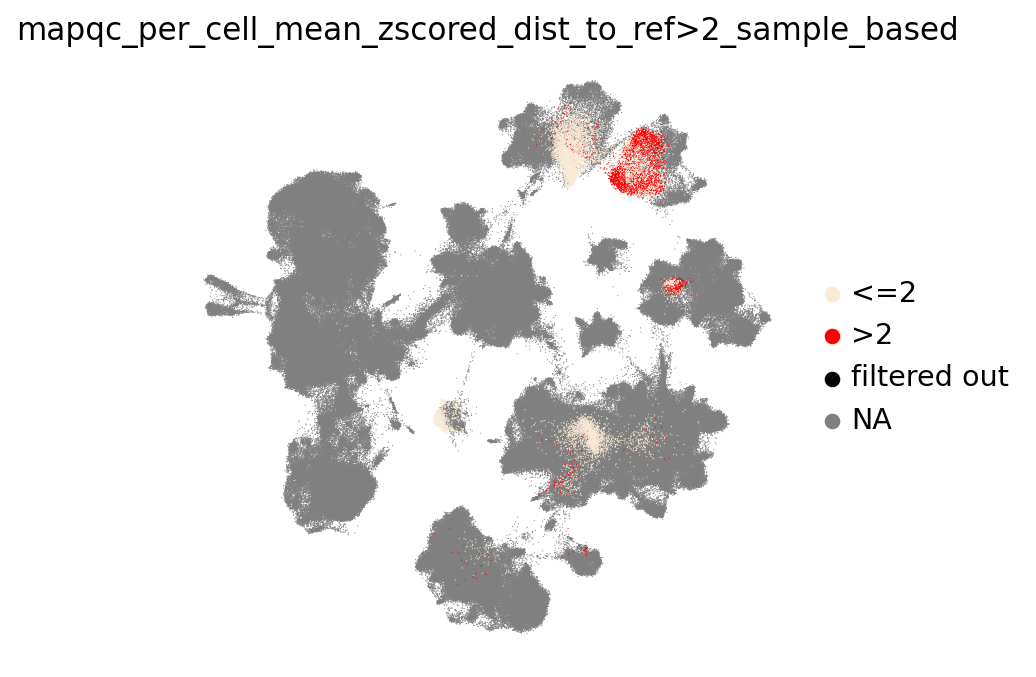

In [76]:
plotting.plot_umap_cell_level_results(results_disease_2, size=1)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


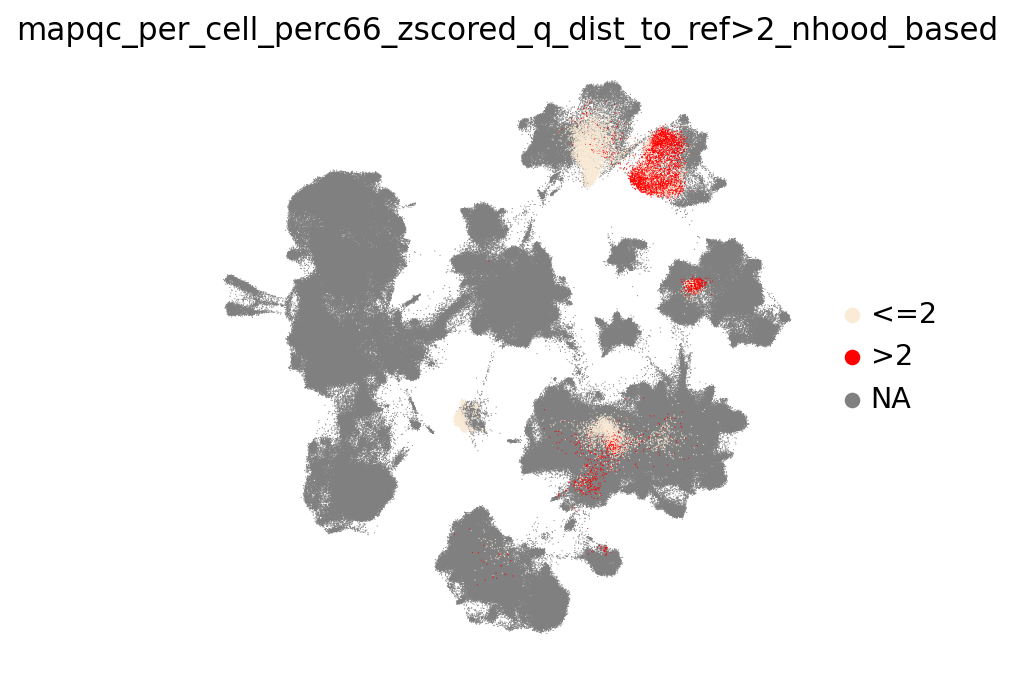

In [77]:
plotting.plot_umap_cell_level_results(results_disease_2, size=1, sample_based=False)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


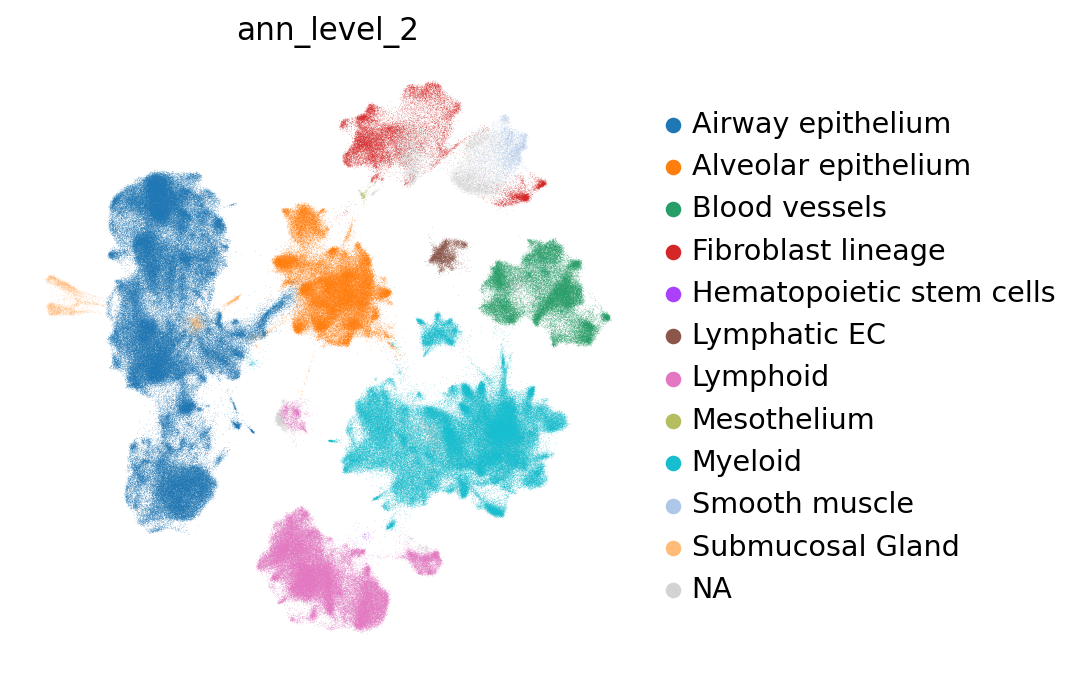

In [78]:
sc.pl.umap(adata_disease_2, color="ann_level_2", frameon=False)

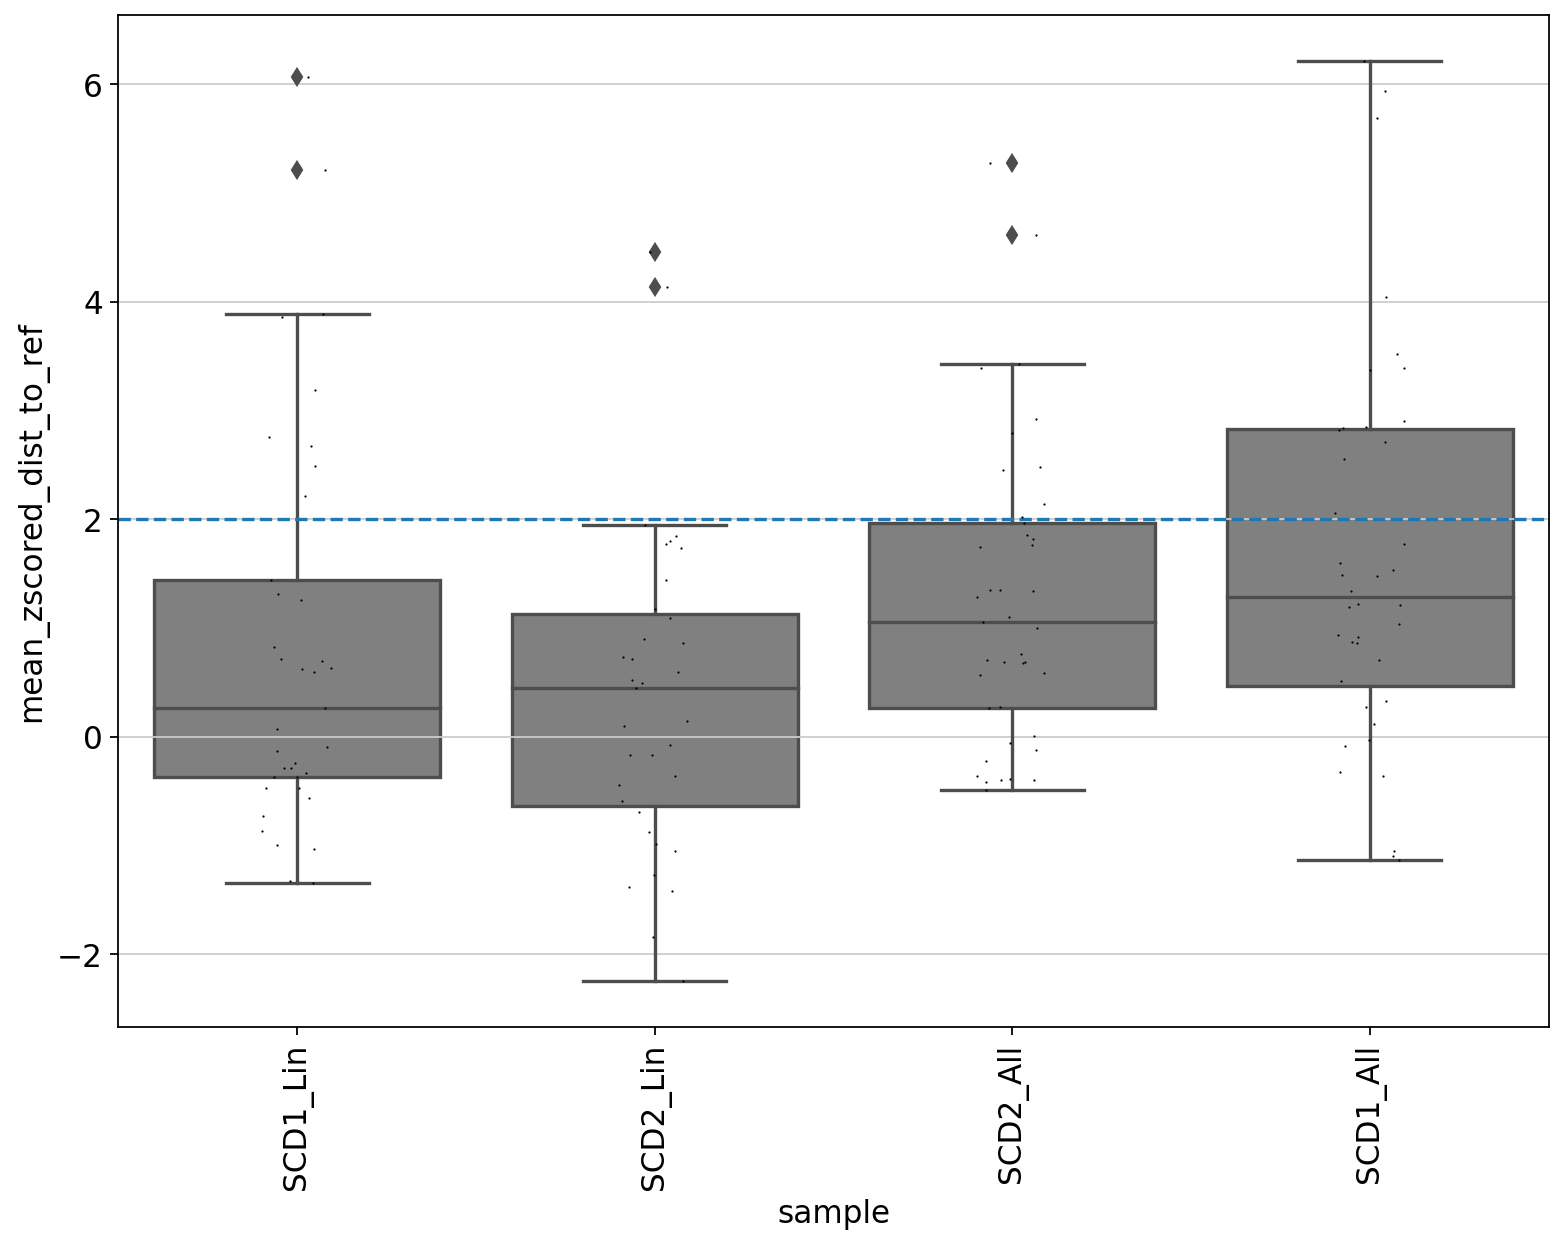

In [79]:
plotting.plot_sample_distances_to_reference(results_disease_2)

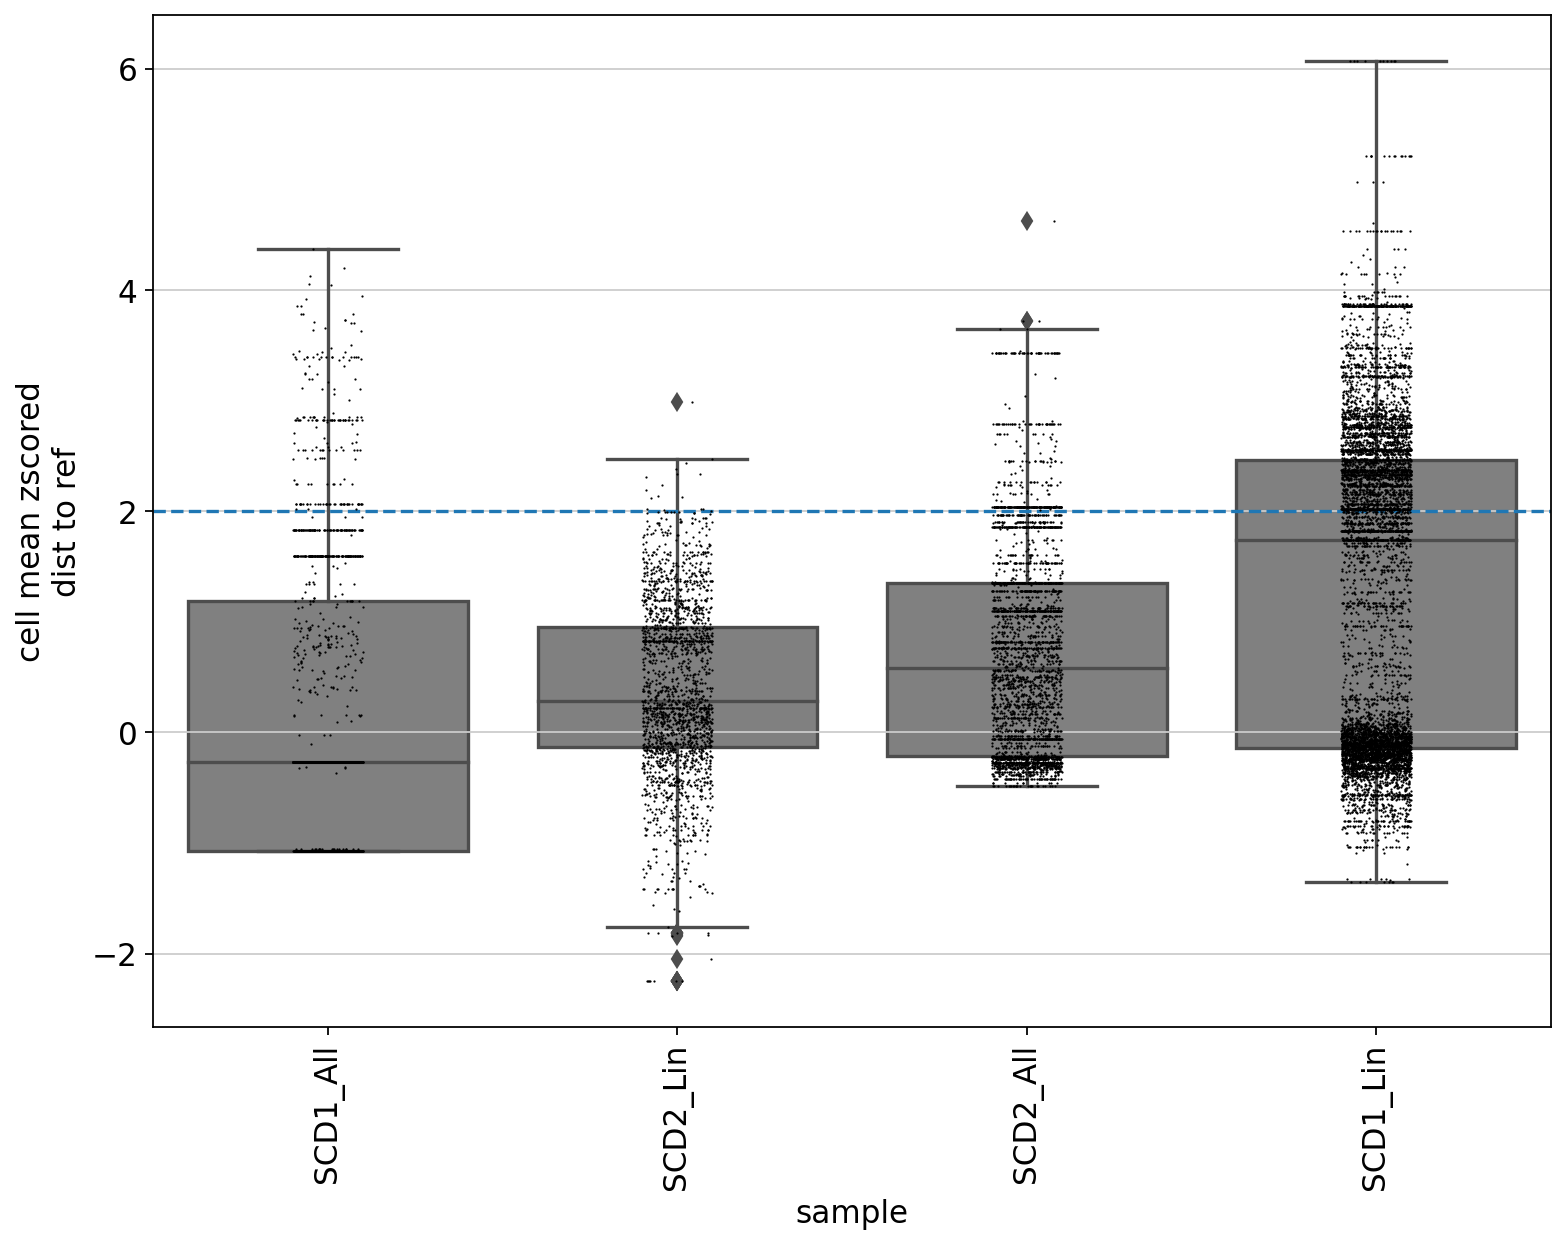

In [80]:
plotting.plot_sample_distances_to_reference_cell_level(results_disease_2)

### Store results:

In [83]:
results_healthy.save(os.path.join(dir_mapped_results, "mapqc_results_healthy.pkl"))
results_disease.save(os.path.join(dir_mapped_results, "mapqc_results_disease.pkl"))

saving results at ../../../results/HLCA/Sheppard/Sheppard_2020_kl1_sample_as_batch/mapqc_results_healthy.pkl
saving results at ../../../results/HLCA/Sheppard/Sheppard_2020_kl1_sample_as_batch/mapqc_results_disease.pkl
